# 03 · Análise

**Pergunta.** Quais municípios sustentam o acesso à internação de urgência pelo SUS no RN, e quanto o acesso de cada município depende de um único polo? Se um polo deixar de atender, quantas internações são afetadas, quais municípios ficam sem alternativa e para onde os pacientes teriam de ir?

**Quem se beneficia.** A Secretaria de Saúde do RN e as Comissões Intergestores Regionais, que planejam a regionalização: quais polos não podem parar, onde reforçar a rede e quais municípios precisam de plano de contingência.

**Por que é uma pergunta de rede.** A resposta depende de quem envia pacientes para quem, e não do tamanho de cada município isolado.

**Entradas** (geradas por `01_coleta` e `02_rede`): `rd_rn_2024.parquet`, `municipios_rn.csv`, `coordenadas_rn.csv`, `distancias_rn.csv`, `hospitais_rn.csv`.

**Saídas:** figuras em `figures/`; para o Gephi (seção 9), `data/processed/rede_rn_2024_urgencia.graphml` e `data/processed/rede_hospitais_jaccard_2024.graphml`; atributos dos municípios em `data/processed/nos_rn_2024_urgencia.csv`.

### Conteúdo do curso usado em cada seção

| conceito | semana · notebook do professor | seção |
|---|---|---|
| Rede multicamada e subgrafo | S2 · `lesson03` | 1.1 |
| Densidade e esparsidade | S2 · `lesson03` | 1.2 |
| Grau de entrada e de saída, distribuição de grau | S2 · `lesson03` | 1.3 |
| Matriz de adjacência (dirigida, com pesos e diagonal) | S2 · `lesson03`, S4 · `dataviz` | 1.4 |
| BFS (`bfs_layers`) para formar as bacias | S3 · `lesson04`, `wikipedia` | 1.4 |
| Componentes conexas, GCC, WCC e SCC; remoção de polos | S4 · `lesson05`, `practice` §5, §6 e §8 | 3.1, 3.2 |
| Centralidades (grau de entrada e de saída, força de entrada, closeness, betweenness) e ECDF | S4 · `lesson06`, `hubs` §4–6 | 4 |
| Centralidade contra remoção: quem parece importante e quem causa dano | S4 · `hubs` §7 | 4.6 |
| Remoção de nós: ataque dirigido contra falha aleatória | S4 · `hubs` §7, `practice` §8 | 5 |
| k-core, k-shell, hub contra núcleo | S5 · `lesson07` | 6 |
| Rede bipartida, projeção, artefato do clique, Jaccard; remoção de hospital e sensibilidade ao limiar | S6 · `lesson08` | 7 |
| Esqueleto por limiar de peso | S6 · `lesson08` §5.7 | 8 |

## Preparação

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from networkx.algorithms import bipartite

PROCESSED = Path("data/processed")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
ANO = 2024
LIMIAR = 10      # internações/ano para uma ligação contar como rota estabelecida (seções 5, 7 e 8)
SEMENTE = 42

# paleta: categorias em ordem fixa (azul, laranja, verde-água); cinza para contexto
AZUL, LARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
CINZA, TINTA, TINTA_2, FUNDO = "#c3c2b7", "#0b0b0b", "#52514e", "#fcfcfb"
AZUIS = LinearSegmentedColormap.from_list("azuis", [FUNDO, "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
VERDES = LinearSegmentedColormap.from_list("verdes", [FUNDO, "#c6efdc", "#5fcf9f", "#1baf7a", "#0d6b4a"])
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def salvar(fig, arquivo):
    fig.savefig(FIGURES / arquivo)

def milhar(x):
    """Separador de milhar brasileiro: 1234 -> 1.234."""
    return f"{x:,.0f}".replace(",", ".")

In [2]:
df = pd.read_parquet(PROCESSED / f"rd_rn_{ANO}.parquet")
df = df[(df["IDENT"] == "1") & df["NOME_RES"].notna()]  # mesmos filtros de 02_rede

nome = pd.read_csv(PROCESSED / "municipios_rn.csv", dtype={"cod6": str}).set_index("cod6")["nome"]
cod = pd.Series(nome.index, index=nome.values)  # nome -> código IBGE
coord = pd.read_csv(PROCESSED / "coordenadas_rn.csv", dtype={"cod6": str}).set_index("cod6")
dist = pd.read_csv(PROCESSED / "distancias_rn.csv", dtype={"origem": str, "destino": str})
dist = dist.set_index(["origem", "destino"])
hospital = pd.read_csv(PROCESSED / "hospitais_rn.csv", dtype={"cnes": str}).set_index("cnes")["nome_hospital"]

def horas(o, d):
    """Tempo de carro entre as sedes (OSRM). Zero dentro do próprio município."""
    return 0.0 if o == d else dist.at[(o, d), "horas"]

print(f"Internações analisadas: {len(df):,}")

Internações analisadas: 214,034


## 1. A rede e suas camadas

*Semana 2 · `lesson03`: redes multicamada, subgrafos, densidade e esparsidade, grau de entrada e de saída, matriz de adjacência.*

Antes de responder à pergunta, a rede é descrita com o conteúdo da semana 2:

- **1.1** camadas e subgrafos: urgência e eletiva;
- **1.2** densidade e esparsidade;
- **1.3** grau de entrada e de saída;
- **1.4** matriz de adjacência, com a autossuficiência na diagonal.

### 1.1 Duas camadas de internações hospitalares: urgência e eletiva

Uma rede **multicamada** tem os mesmos nós e mais de um tipo de relação. Aqui a relação é sempre "envia pacientes para", mas separada pelo caráter da internação (`CAR_INT`):

- **eletiva** (`01`): internação agendada;
- **urgência** (`02`, `05`, `06`): `02` Urgência; `05` Outros tipos de acidente de trânsito; `06` Outros tipos de lesões e envenenamentos por agentes químicos ou físicos.

Cada camada é um **subgrafo** da rede total: tem os mesmos 167 municípios e só parte das internações, e toda ligação de uma camada também existe na rede total.

Os códigos `03` (acidente no local de trabalho ou a serviço da empresa) e `04` (acidente no trajeto para o trabalho) não aparecem nas AIHs do RN em 2024.

Resolvi tratar diretamente urgência, pois urgência deve ser atendido o quanto antes.

In [3]:
df.groupby(["CAMADA", "CAR_INT"]).size().rename("internações")

CAMADA    CAR_INT
eletiva   01          79874
urgencia  02         122858
          05           3980
          06           7322
Name: internações, dtype: int64

Nesse caso aqui, temos 134.157 internações de urgência e 79874 internações de carater eletivo.

In [4]:
def construir_rede(d):
    """Residência -> internação, só entre municípios diferentes (como em 02_rede).

    weight: internações no ano. dist: 1/weight, para os algoritmos de caminho,
    que tratam o peso como custo (semana 4, practice)."""
    fora = d[d["MUNIC_RES"] != d["MUNIC_MOV"]]
    G = nx.DiGraph()
    G.add_nodes_from(nome.index)
    for (o, v), w in fora.groupby(["MUNIC_RES", "MUNIC_MOV"]).size().items():
        G.add_edge(o, v, weight=int(w), dist=1 / w)
    locais = d[d["MUNIC_RES"] == d["MUNIC_MOV"]].groupby("MUNIC_RES").size()
    nx.set_node_attributes(G, locais.reindex(nome.index, fill_value=0).to_dict(), "locais")
    return G

camadas = {
    "total": construir_rede(df),
    "urgencia": construir_rede(df[df["CAMADA"] == "urgencia"]),
    "eletiva": construir_rede(df[df["CAMADA"] == "eletiva"]),
}
U = camadas["urgencia"]

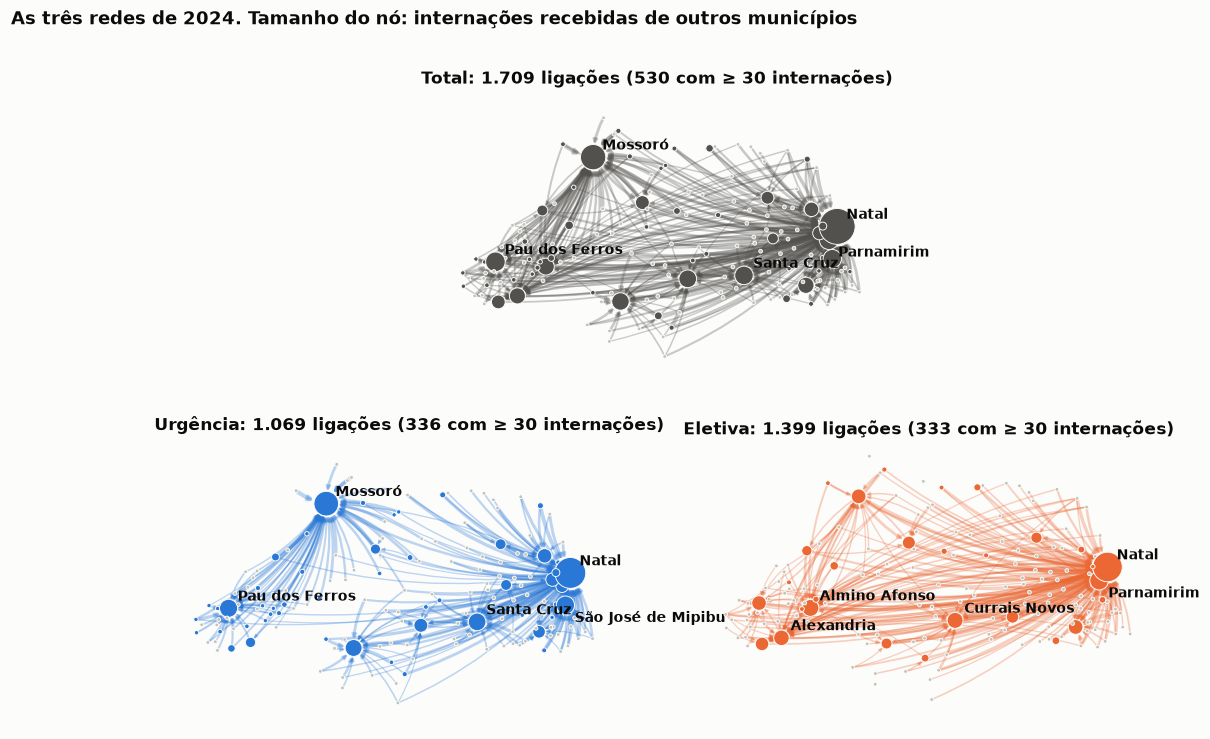

In [5]:
PESO_MIN = 30
pos = {c: (coord.at[c, "longitude"], coord.at[c, "latitude"]) for c in nome.index}
estilo = {"total": ("Total", TINTA_2), "urgencia": ("Urgência", AZUL), "eletiva": ("Eletiva", LARANJA)}
deslocamento = {"Parnamirim": (6, -11), "São José de Mipibu": (6, -11)}

fig, axs = plt.subplot_mosaic([[".", "total", "total", "."], ["urgencia", "urgencia", "eletiva", "eletiva"]],
                              figsize=(12, 7.5))
for c, G in camadas.items():
    ax = axs[c]
    rotulo, cor = estilo[c]
    fortes = [(o, v) for o, v, w in G.edges(data="weight") if w >= PESO_MIN]
    peso = np.array([G[o][v]["weight"] for o, v in fortes])
    forca_c = pd.Series(dict(G.in_degree(weight="weight")))
    nodelist = list(G)
    tamanho = [6 + 2.2 * np.sqrt(forca_c[n]) for n in nodelist]  # mesma escala nas três camadas
    nx.draw_networkx_edges(G, pos, edgelist=fortes, ax=ax, width=0.3 + 1.5 * np.log10(peso / PESO_MIN + 1),
                           edge_color=cor, alpha=0.3, arrows=True, arrowstyle="-|>", arrowsize=5,
                           connectionstyle="arc3,rad=0.12", nodelist=nodelist, node_size=tamanho)
    nx.draw_networkx_nodes(G, pos, nodelist=nodelist, node_size=tamanho,
                           node_color=[cor if forca_c[n] > 0 else CINZA for n in nodelist],
                           edgecolors=FUNDO, linewidths=0.6, ax=ax)
    for n in forca_c.nlargest(5).index:
        ax.annotate(nome[n], pos[n], xytext=deslocamento.get(nome[n], (6, 5)), textcoords="offset points",
                    fontsize=9, fontweight="bold", color=TINTA)
    arestas = f"{G.number_of_edges():,}".replace(",", ".")
    ax.set_title(f"{rotulo}: {arestas} ligações ({len(fortes)} com ≥ {PESO_MIN} internações)",
                 fontsize=11)
    ax.set_aspect("equal")
    ax.axis("off")
fig.suptitle(f"As três redes de {ANO}. Tamanho do nó: internações recebidas de outros municípios",
             x=0.02, ha="left", fontsize=12, fontweight="bold")
salvar(fig, "01_redes_por_camada.png")
plt.show()

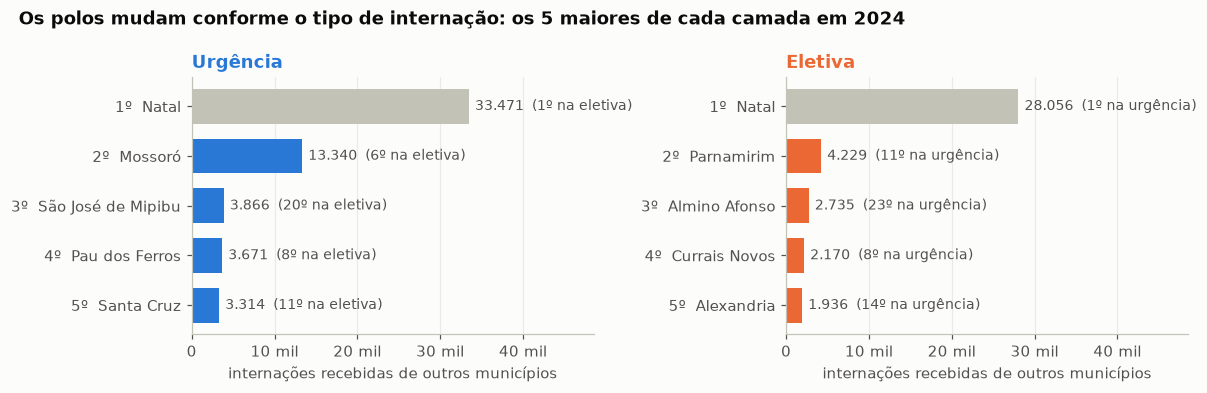

In [6]:
forca = pd.DataFrame({c: pd.Series(dict(G.in_degree(weight="weight"))) for c, G in camadas.items()})
forca.index = forca.index.map(nome)
posicao = forca.rank(ascending=False, method="min").astype(int)
TOP = 5
tops = {c: forca[c].nlargest(TOP).index for c in ["urgencia", "eletiva"]}
nos_dois = tops["urgencia"].intersection(tops["eletiva"])  # polo nas duas camadas: cinza

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, (c, outra, rotulo, cor) in zip(axs, [("urgencia", "eletiva", "Urgência", AZUL),
                                             ("eletiva", "urgencia", "Eletiva", LARANJA)]):
    t = forca.loc[tops[c], c]
    y = np.arange(TOP)[::-1]
    ax.barh(y, t, height=0.7, color=[CINZA if m in nos_dois else cor for m in t.index])
    ax.set_yticks(y, [f"{i}º  {m}" for i, m in enumerate(t.index, 1)])
    for yi, (m, v) in zip(y, t.items()):
        ax.annotate(f"{milhar(v)}  ({posicao.at[m, outra]}º na {'eletiva' if outra == 'eletiva' else 'urgência'})",
                    (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA_2)
    ax.set_title(rotulo, color=cor)
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, forca[["urgencia", "eletiva"]].max().max() * 1.45)
    ax.set_xlabel("internações recebidas de outros municípios")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:.0f} mil" if x else "0")
fig.suptitle(f"Os polos mudam conforme o tipo de internação: os {TOP} maiores de cada camada em {ANO}",
             x=0.02, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
salvar(fig, "01_polos_por_camada.png")
plt.show()

Alguns polos da camada eletiva não aparecem na urgência. A tabela abaixo mostra por quê: eles recebem quase só cirurgias agendadas, concentradas em um diagnóstico e um hospital. É o padrão de um mutirão ou contrato de cirurgias, uma decisão de gestão, e não a geografia do atendimento.

In [7]:
recebidas = df[df["MUNIC_RES"] != df["MUNIC_MOV"]]
linhas = []
for cidade in ["Almino Afonso", "Currais Novos", "Santo Antônio", "Mossoró", "Santa Cruz"]:
    r = recebidas[recebidas["NOME_MOV"] == cidade]
    cid = r["DIAG_PRINC"].str[:3].value_counts()
    linhas.append({"polo": cidade, "recebidas": len(r), "fração eletiva": (r["CAMADA"] == "eletiva").mean(),
                   "hospitais": r["CNES"].nunique(), "CID mais comum": cid.index[0],
                   "fração desse CID": cid.iloc[0] / len(r)})
pd.DataFrame(linhas).set_index("polo").round(2)

,recebidas,fração eletiva,hospitais,CID mais comum,fração desse CID
polo,,,,,
Almino Afonso,2741,1.00,1,H25,0.43
Currais Novos,3382,0.64,2,K80,0.25
Santo Antônio,2303,0.66,1,K80,0.15
Mossoró,14877,0.10,9,O82,0.08
Santa Cruz,4083,0.19,2,O80,0.23


**O que 1.1 mostra.**

- Os polos de urgência são geográficos: Mossoró recebe 13 mil internações de urgência e só 1,5 mil eletivas.
- Almino Afonso recebe 2.741 internações de 128 municípios, mas 100% são eletivas, em um único hospital, e 43% são catarata (CID H25). Currais Novos e Santo Antônio têm o mesmo padrão, com vesícula (K80). Na rede agregada eles pareceriam polos regionais; separar as camadas evita essa leitura errada.
- No SIH, parto conta como urgência. Por isso São José de Mipibu e Santa Cruz, sedes de maternidades regionais, aparecem entre os polos de urgência (em Santa Cruz o CID mais comum é O80, parto normal).

### 1.2 Densidade e esparsidade

Numa rede dirigida com *n* nós, cada par ordenado de municípios pode ter uma ligação: são *n*(*n* − 1) ligações possíveis, aqui 167 × 166 = 27.722. A **densidade** é a fração delas que existe, e a **esparsidade** é o que falta (1 − densidade). O **grau médio de saída** (arestas ÷ nós) diz para quantos municípios diferentes, em média, cada um manda pacientes. Em rede dirigida ele é igual ao grau médio de entrada, porque toda aresta sai de um nó e chega em outro.

As internações da tabela são só as que saem do município de residência. As internações no próprio município não viram aresta; elas aparecem na diagonal da matriz, na seção 1.4.

In [8]:
def resumo(G):
    n, m = G.number_of_nodes(), G.number_of_edges()
    forca = pd.Series(dict(G.in_degree(weight="weight")))
    return pd.Series({
        "municípios (nós)": n,
        "ligações possíveis: n(n - 1)": n * (n - 1),
        "ligações existentes (arestas)": m,
        "densidade": nx.density(G),
        "esparsidade: 1 - densidade": 1 - nx.density(G),
        "destinos por município (grau médio de saída)": m / n,
        "internações fora do município de residência": forca.sum(),
        "municípios que recebem pacientes de fora": (pd.Series(dict(G.in_degree())) > 0).sum(),
        "fração dessas internações que vai para Natal": forca[cod["Natal"]] / forca.sum(),
        "fração que vai para os 5 maiores polos": forca.nlargest(5).sum() / forca.sum(),
    })

pd.DataFrame({c: resumo(G) for c, G in camadas.items()}).round(3)

,total,urgencia,eletiva
municípios (nós),167.000,167.000,167.000
ligações possíveis: n(n - 1),27722.000,27722.000,27722.000
ligações existentes (arestas),1709.000,1069.000,1399.000
densidade,0.062,0.039,0.050
esparsidade: 1 - densidade,0.938,0.961,0.950
destinos por município (grau médio de saída),10.234,6.401,8.377
internações fora do município de residência,115558.000,67458.000,48100.000
municípios que recebem pacientes de fora,57.000,52.000,29.000
fração dessas internações que vai para Natal,0.532,0.496,0.583
fração que vai para os 5 maiores polos,0.784,0.855,0.813


**O que 1.2 mostra.**

- **A rede é esparsa.** Das 27.722 ligações possíveis, a rede total tem 1.709 (densidade 0,062). Na urgência são 1.069 (0,039): 96% dos pares de municípios não trocam nenhum paciente de urgência no ano.
- **Poucos destinos por município.** Na urgência, cada município manda pacientes para 6,4 destinos em média; na eletiva, para 8,4.
- **Urgência regional, eletiva em Natal.** Na urgência, 52 municípios recebem pacientes de fora e os 5 maiores polos ficam com 85% das internações que saem do município de residência. Na eletiva, só 29 recebem e Natal sozinho fica com 58% (50% na urgência). A urgência se espalha pelos polos regionais; a eletiva converge para Natal e para os mutirões.

### 1.3 Grau de entrada e de saída

Daqui em diante a rede é só a camada de **urgência**, a que responde à pergunta. A figura abaixo repete essa camada do mapa da seção 1.1, mas nesse caso só a de urgência.

- **Grau de entrada:** de quantos municípios diferentes o município recebe pacientes. Na matriz da seção 1.4, é o número de células preenchidas na coluna (fora da diagonal).
- **Grau de saída:** para quantos municípios diferentes ele envia pacientes; na matriz, as células preenchidas na linha.
- **Força de entrada e de saída:** o mesmo, somando as internações em vez de contar os municípios.
- **Carga:** internações de urgência atendidas no município (as dos próprios residentes mais as recebidas).

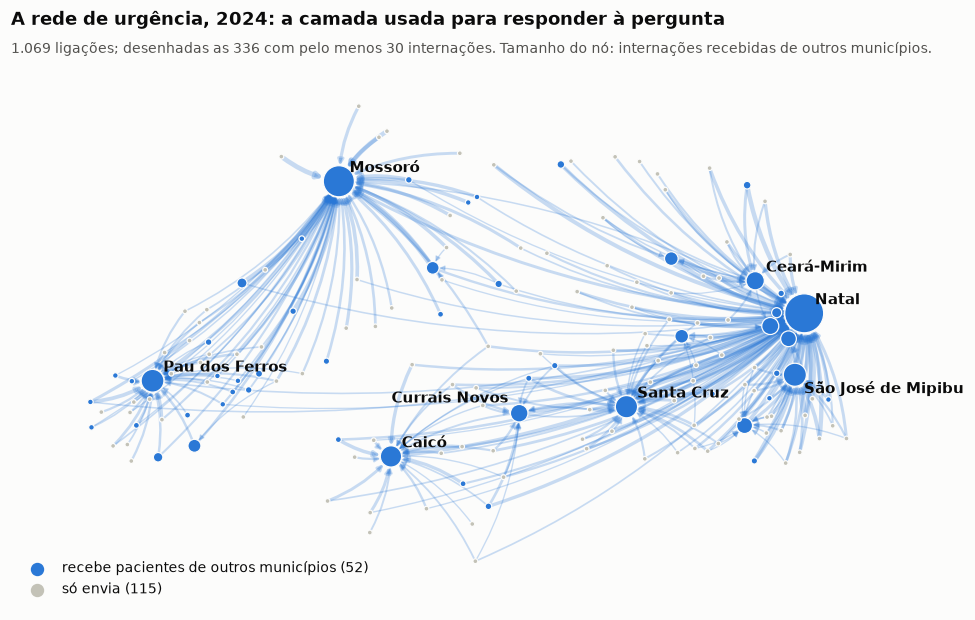

In [9]:
fortes = [(o, v) for o, v, w in U.edges(data="weight") if w >= PESO_MIN]
peso = np.array([U[o][v]["weight"] for o, v in fortes])
forca_u = pd.Series(dict(U.in_degree(weight="weight")))
recebe_u = pd.Series(dict(U.in_degree())) > 0
nodelist = list(U)
tamanho = [10 + 3.5 * np.sqrt(forca_u[n]) for n in nodelist]

fig, ax = plt.subplots(figsize=(11, 6.5))
nx.draw_networkx_edges(U, pos, edgelist=fortes, ax=ax, width=0.3 + 1.8 * np.log10(peso / PESO_MIN + 1),
                       edge_color=AZUL, alpha=0.25, arrows=True, arrowstyle="-|>", arrowsize=7,
                       connectionstyle="arc3,rad=0.12", nodelist=nodelist, node_size=tamanho)
nx.draw_networkx_nodes(U, pos, nodelist=nodelist, node_size=tamanho,
                       node_color=[AZUL if recebe_u[n] else CINZA for n in nodelist],
                       edgecolors=FUNDO, linewidths=0.8, ax=ax)
deslocamento = {"São José de Mipibu": (6, -12), "Currais Novos": (-7, 7)}
for n in forca_u.nlargest(8).index:
    dx, dy = deslocamento.get(nome[n], (7, 6))
    ax.annotate(nome[n], pos[n], xytext=(dx, dy), textcoords="offset points", fontsize=9.5, fontweight="bold",
                color=TINTA, ha="right" if dx < 0 else "left")
ax.scatter([], [], s=60, color=AZUL, label=f"recebe pacientes de outros municípios ({recebe_u.sum()})")
ax.scatter([], [], s=60, color=CINZA, label=f"só envia ({(~recebe_u).sum()})")
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"A rede de urgência, {ANO}: a camada usada para responder à pergunta", pad=22)
ax.text(0, 1.01, f"{milhar(U.number_of_edges())} ligações; desenhadas as {len(fortes)} com pelo menos {PESO_MIN} "
        "internações. Tamanho do nó: internações recebidas de outros municípios.",
        transform=ax.transAxes, fontsize=9, color=TINTA_2)
salvar(fig, "01_rede_urgencia.png")
plt.show()

In [10]:
nos = pd.DataFrame(index=nome.index)
nos["nome"] = nome
nos["grau_entrada"] = pd.Series(dict(U.in_degree()))
nos["grau_saida"] = pd.Series(dict(U.out_degree()))
nos["forca_entrada"] = pd.Series(dict(U.in_degree(weight="weight")))
nos["forca_saida"] = pd.Series(dict(U.out_degree(weight="weight")))
nos["locais"] = pd.Series(nx.get_node_attributes(U, "locais"))
nos["residentes"] = nos["locais"] + nos["forca_saida"]
nos["autossuficiencia"] = nos["locais"] / nos["residentes"]
nos["carga"] = nos["locais"] + nos["forca_entrada"]

recebe = nos["grau_entrada"] > 0
print(f"Recebem pacientes de outros municípios: {recebe.sum()}")
print(f"Só enviam:                              {(~recebe).sum()}")
print(f"Sem nenhuma internação de urgência no próprio município: {(nos['locais'] == 0).sum()}")
print()
acumulado = nos["forca_entrada"].sort_values(ascending=False).cumsum() / nos["forca_entrada"].sum()
for k in [1, 2, 5, 10]:
    print(f"Os {k:2d} maiores polos recebem {acumulado.iloc[k - 1]:.0%} das internações entre municípios")

Recebem pacientes de outros municípios: 52
Só enviam:                              115
Sem nenhuma internação de urgência no próprio município: 83

Os  1 maiores polos recebem 50% das internações entre municípios
Os  2 maiores polos recebem 69% das internações entre municípios
Os  5 maiores polos recebem 85% das internações entre municípios
Os 10 maiores polos recebem 96% das internações entre municípios


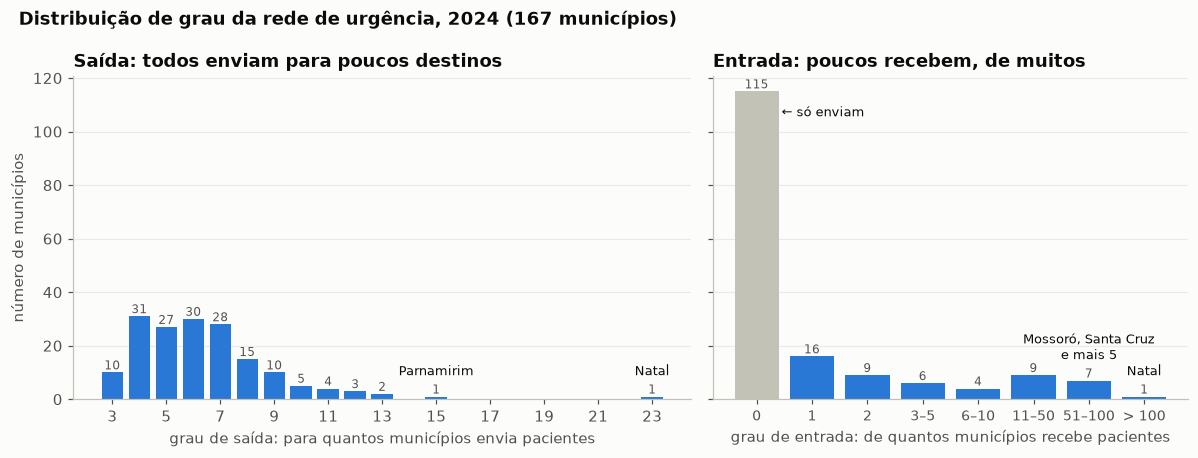

In [11]:
fig, (ax_s, ax_e) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, gridspec_kw={"width_ratios": [1.3, 1]})

# grau de saída: uma barra por valor
saida = nos["grau_saida"].value_counts().sort_index()
ax_s.bar(saida.index, saida.values, width=0.8, color=AZUL)
for k, v in saida.items():
    ax_s.annotate(str(v), (k, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8, color=TINTA_2)
for cidade in ["Natal", "Parnamirim"]:
    k = nos.at[cod[cidade], "grau_saida"]
    ax_s.annotate(cidade, (k, saida[k]), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=8.5,
                  color=TINTA)
ax_s.set_xticks(range(saida.index.min(), saida.index.max() + 1, 2))
ax_s.set_xlabel("grau de saída: para quantos municípios envia pacientes")
ax_s.set_ylabel("número de municípios")
ax_s.set_title("Saída: todos enviam para poucos destinos")

# grau de entrada: faixas, porque vai de 0 a 165
faixas = [(0, 0), (1, 1), (2, 2), (3, 5), (6, 10), (11, 50), (51, 100), (101, 200)]
rotulos = ["0", "1", "2", "3–5", "6–10", "11–50", "51–100", "> 100"]
contagem = [nos["grau_entrada"].between(a, b).sum() for a, b in faixas]
x = np.arange(len(faixas))
ax_e.bar(x, contagem, width=0.8, color=[CINZA] + [AZUL] * (len(faixas) - 1))
for xi, v in zip(x, contagem):
    ax_e.annotate(str(v), (xi, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8, color=TINTA_2)
ax_e.annotate("← só enviam", (0.45, contagem[0] - 8), fontsize=8.5, color=TINTA, va="center")
altos = nos[nos["grau_entrada"].between(51, 100)].sort_values("grau_entrada", ascending=False)["nome"]
ax_e.annotate(f"{altos.iloc[0]}, {altos.iloc[1]}\ne mais {len(altos) - 2}", (6, contagem[6]), xytext=(0, 14),
              textcoords="offset points", ha="center", fontsize=8.5, color=TINTA)
ax_e.annotate("Natal", (7, contagem[7]), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=8.5,
              color=TINTA)
ax_e.set_xticks(x, rotulos, fontsize=9)
ax_e.set_xlabel("grau de entrada: de quantos municípios recebe pacientes")
ax_e.set_title("Entrada: poucos recebem, de muitos")

for ax in (ax_s, ax_e):
    ax.set_axisbelow(True)
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Distribuição de grau da rede de urgência, {ANO} ({len(nos)} municípios)", x=0.02, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
salvar(fig, "01_distribuicao_grau.png")
plt.show()

**O que 1.3 mostra.**

- **Quase todos enviam, poucos recebem.** 52 municípios recebem pacientes de outros municípios e 115 só enviam (grau de entrada 0). 83 não tiveram nenhuma internação de urgência no próprio município em 2024.
- **Distribuição de grau.** As duas distribuições têm formas opostas. O grau de saída é concentrado: todo município envia para 3 a 23 destinos, e 116 dos 167 enviam para 4 a 7. O grau de entrada é muito desigual: 115 municípios têm grau 0, 25 recebem de 1 ou 2 municípios, e poucos polos recebem de dezenas (Mossoró de 99, Santa Cruz de 91, Natal de 165). É a assinatura de uma rede de polos.
- **Concentração.** Natal recebe metade das internações de urgência entre municípios; Natal e Mossoró juntos, 69%; os 10 maiores, 96%.

### 1.4 Matriz de adjacência

*Também semana 3 · `lesson04` e `wikipedia` (BFS, para formar as bacias) e semana 4 · `dataviz` (matrix plot).*

A matriz de adjacência **W** guarda a rede como uma tabela: a linha *i* é o município onde o paciente mora, a coluna *j* é o município onde ele se internou, e W[*i*, *j*] é o número de internações de urgência no ano. Como a rede é **dirigida**, a matriz não é simétrica: W[Caicó, Natal] não é igual a W[Natal, Caicó]. Como é **ponderada**, cada célula guarda um peso, e não só 0 ou 1.

**A diagonal.** No grafo, quem se interna no próprio município não vira laço: esse número fica no atributo `locais`, para não entrar no grau, na densidade nem nos caminhos. Na matriz ele vai para a diagonal W[*i*, *i*]. Dividindo cada linha pelo total de residentes, a linha soma 1 e a diagonal é a **autossuficiência** do município: a fração das urgências dos residentes atendida no próprio município.

**A ordem.** Com os municípios em ordem aleatória, a matriz é ruído. Ordenados pela **bacia** a que pertencem, aparecem blocos. As bacias são formadas com **BFS** (busca em largura), em dois passos:

1. **Cada município aponta para onde seus moradores mais se internam**, contando o próprio município. Jardim de Piranhas: 350 internações em Caicó, 217 no próprio município e 145 em Natal, então aponta para Caicó. Caicó: 2.933 no próprio município e 430 em Natal, então aponta para si mesmo. Quem aponta para si mesmo é um **polo**.
2. **BFS a partir de cada polo, andando contra as setas** (`nx.bfs_layers`, como no `wikipedia.ipynb`). A camada 0 é o polo, a camada 1 são os municípios que apontam direto para ele, a camada 2 os que apontam para alguém da camada 1, e assim por diante. Tudo o que a BFS alcança é a bacia do polo.

Os municípios que apontam para si mesmos e não recebem ninguém formam uma **bacia própria** de um município só. Na matriz, elas vão juntas no fim.

In [12]:
def destino_mais_usado(o):
    candidatos = {v: U[o][v]["weight"] for v in U.successors(o)}
    candidatos[o] = U.nodes[o]["locais"]
    return max(candidatos, key=candidatos.get)

# cada município aponta para onde seus moradores mais se internam (para si mesmo, se for o próprio município)
passo = {o: destino_mais_usado(o) for o in U}
aponta = nx.DiGraph()
aponta.add_nodes_from(U)
aponta.add_edges_from((o, v) for o, v in passo.items() if o != v)
polos_bacia = [o for o, v in passo.items() if o == v]

# BFS a partir de cada polo, andando contra as setas (semana 3, wikipedia §2.2):
# camada 0 = o polo, camada 1 = quem aponta direto para ele, camada 2 = quem aponta para a camada 1...
volta = aponta.reverse()
nos["bacia"], nos["camada_bfs"] = None, -1
for polo in polos_bacia:
    for k, camada in enumerate(nx.bfs_layers(volta, polo)):
        nos.loc[camada, "bacia"] = polo
        nos.loc[camada, "camada_bfs"] = k
assert (nos["camada_bfs"] >= 0).all()  # todo município chega a um polo

tamanho = nos["bacia"].value_counts()
print(f"Polos (apontam para si mesmos): {len(polos_bacia)}; bacias de um município só: {(tamanho == 1).sum()}")
print("Municípios por camada da BFS:", nos["camada_bfs"].value_counts().sort_index().to_dict())
print("\nCamadas da bacia de Caicó:")
for k, camada in enumerate(nx.bfs_layers(volta, cod["Caicó"])):
    print(f"  {k}: {', '.join(sorted(nome[c] for c in camada))}")
print("\nQuem está na camada 2 ou mais:")
for o in nos.index[nos["camada_bfs"] >= 2]:
    print(f"  {nome[o]} -> {nome[passo[o]]} -> {nome[passo[passo[o]]]}")
print()
tamanho[tamanho > 1].rename(index=nome).rename("municípios na bacia")

Polos (apontam para si mesmos): 26; bacias de um município só: 21
Municípios por camada da BFS: {0: 26, 1: 140, 2: 1}

Camadas da bacia de Caicó:
  0: Caicó
  1: Cruzeta, Ipueira, Jardim de Piranhas, Ouro Branco, Santana do Seridó, Serra Negra do Norte, São Fernando, São José do Seridó, São João do Sabugi, Timbaúba dos Batistas

Quem está na camada 2 ou mais:
  Várzea -> São José de Mipibu -> Natal



bacia
Natal             78
Mossoró           29
Pau dos Ferros    22
Caicó             11
Santa Cruz         6
Name: municípios na bacia, dtype: int64

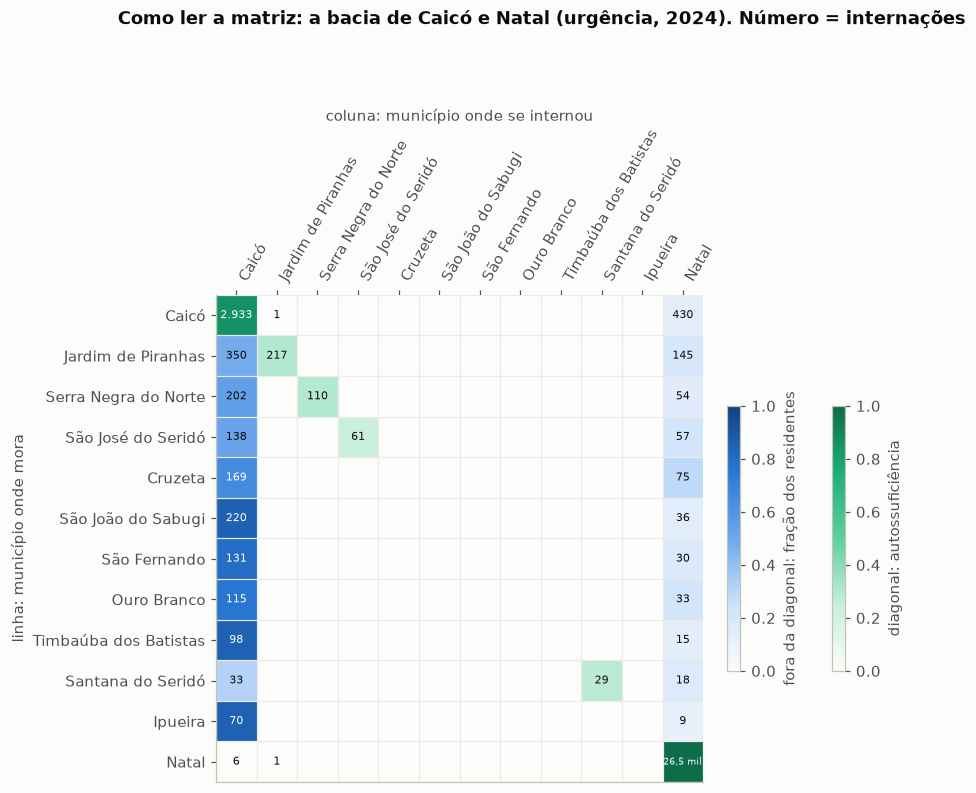

In [13]:
def matriz(G, ordem):
    """Matriz de pesos na ordem dada, com as internações no próprio município na diagonal."""
    W = nx.to_numpy_array(G, nodelist=ordem, weight="weight")
    np.fill_diagonal(W, [G.nodes[o]["locais"] for o in ordem])
    return W

def desenhar(ax, F):
    """Fora da diagonal em azul (foi para outro município), diagonal em verde (ficou no próprio)."""
    diag = np.eye(len(F), dtype=bool)
    fora = ax.imshow(np.ma.masked_where(diag | (F == 0), F), cmap=AZUIS, vmin=0, vmax=1, interpolation="nearest")
    dentro = ax.imshow(np.ma.masked_where(~diag | (F == 0), F), cmap=VERDES, vmin=0, vmax=1, interpolation="nearest")
    ax.grid(False)
    return fora, dentro

# exemplo pequeno: a bacia de Caicó e Natal
EXEMPLO = "Caicó"
membros = nos[nos["bacia"] == cod[EXEMPLO]].sort_values("residentes", ascending=False).index
ordem_ex = [cod[EXEMPLO]] + [o for o in membros if o != cod[EXEMPLO]] + [cod["Natal"]]
W_ex = matriz(U, ordem_ex)
F_ex = W_ex / nos.loc[ordem_ex, "residentes"].to_numpy()[:, None]  # fração do total de residentes da linha

fig, ax = plt.subplots(figsize=(8.5, 8.5))
fora, dentro = desenhar(ax, F_ex)
for i in range(len(ordem_ex)):
    for j in range(len(ordem_ex)):
        if W_ex[i, j]:
            grande = W_ex[i, j] >= 10_000
            texto = f"{W_ex[i, j] / 1000:.1f} mil".replace(".", ",") if grande else milhar(W_ex[i, j])
            ax.text(j, i, texto, ha="center", va="center", fontsize=6 if grande else 7.5,
                    color=FUNDO if F_ex[i, j] > 0.55 else TINTA)
rotulos_ex = [nome[o] for o in ordem_ex]
ax.set_yticks(range(len(ordem_ex)), rotulos_ex)
ax.set_xticks(range(len(ordem_ex)), rotulos_ex)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.setp(ax.get_xticklabels(), rotation=60, ha="left")
ax.set_xticks(np.arange(-0.5, len(ordem_ex)), minor=True)
ax.set_yticks(np.arange(-0.5, len(ordem_ex)), minor=True)
ax.grid(which="minor", color="#ebeae6", lw=0.8)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("coluna: município onde se internou")
ax.set_ylabel("linha: município onde mora")
fig.colorbar(dentro, ax=ax, shrink=0.45, pad=0.02, label="diagonal: autossuficiência")
fig.colorbar(fora, ax=ax, shrink=0.45, pad=0.04, label="fora da diagonal: fração dos residentes")
fig.suptitle(f"Como ler a matriz: a bacia de {EXEMPLO} e Natal (urgência, {ANO}). Número = internações",
             x=0.02, y=0.99, ha="left", fontsize=12, fontweight="bold")
fig.subplots_adjust(top=0.74)
salvar(fig, "01_matriz_exemplo.png")
plt.show()

**Como ler o exemplo.** Cada linha mostra para onde foram as internações de urgência de quem mora naquele município.

- **Diagonal (verde).** Caicó atendeu 2.933 internações dos próprios moradores e Natal, 26,5 mil. Cruzeta, São João do Sabugi, São Fernando e outros têm a diagonal vazia: nenhuma internação de urgência no próprio município.
- **Coluna do polo.** A primeira coluna é Caicó: todos os municípios da bacia mandam pacientes para lá. A última é Natal, a segunda opção de todos.
- **Não é simétrica.** Caicó manda 430 internações para Natal, e Natal manda 6 para Caicó.
- **Esparsa.** A maior parte das células está vazia: os municípios pequenos não trocam pacientes entre si.

As linhas não somam 100% porque o exemplo mostra só 12 dos 167 municípios. Na matriz completa, abaixo, cada linha soma 100%.

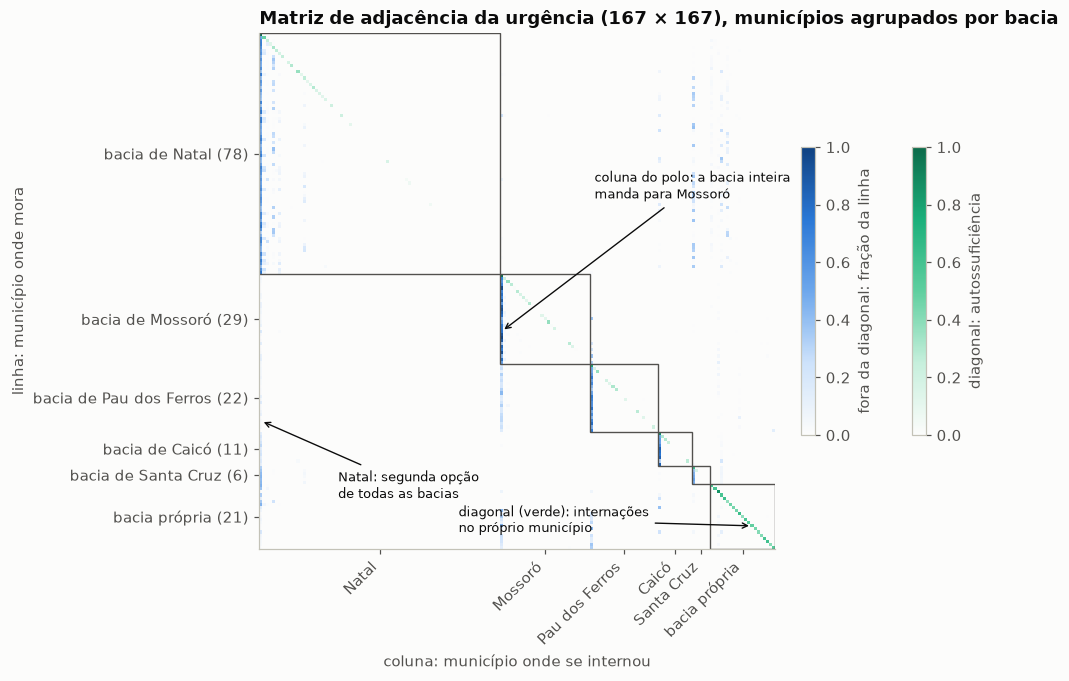

Diagonal vazia (nenhuma internação no próprio município): 83 municípios
Autossuficiência mediana por grupo:
bacia
Caicó             0.00
Mossoró           0.11
Natal             0.00
Pau dos Ferros    0.06
Santa Cruz        0.00
bacia própria     0.52


In [14]:
# as bacias de um município só (o município é o próprio polo) vão juntas no fim
PROPRIA = "bacia própria"
grupo = nos["bacia"].where(nos["bacia"].map(tamanho) > 1, PROPRIA)
tam_grupo = grupo.value_counts()
ordem = sorted(nos.index, key=lambda o: (grupo[o] == PROPRIA, -tam_grupo[grupo[o]], grupo[o],
                                         o != nos.at[o, "bacia"], -nos.at[o, "residentes"]))
W = matriz(U, ordem)
F = W / W.sum(axis=1, keepdims=True)  # cada linha soma 1; a diagonal é a autossuficiência

fig, ax = plt.subplots(figsize=(9, 8.5))
fora, dentro = desenhar(ax, F)
inicio, ticks = 0, []
grupos = pd.unique(grupo[ordem])
for g in grupos:
    n = tam_grupo[g]
    ax.add_patch(Rectangle((inicio - 0.5, inicio - 0.5), n, n, fill=False, ec=TINTA_2, lw=0.9))
    ticks.append(inicio + n / 2 - 0.5)
    inicio += n
ax.set_yticks(ticks, [f"{PROPRIA} ({tam_grupo[g]})" if g == PROPRIA else f"bacia de {nome[g]} ({tam_grupo[g]})"
                      for g in grupos])
ax.set_xticks(ticks, [PROPRIA if g == PROPRIA else nome[g] for g in grupos], rotation=45, ha="right")
ax.set_xlabel("coluna: município onde se internou")
ax.set_ylabel("linha: município onde mora")
ax.set_title(f"Matriz de adjacência da urgência ({len(ordem)} × {len(ordem)}), municípios agrupados por bacia")
seta = dict(arrowstyle="->", color=TINTA, lw=0.9)
p = ordem.index(cod["Mossoró"])
ax.annotate("coluna do polo: a bacia inteira\nmanda para Mossoró", (p, p + 18), xytext=(p + 30, p - 25),
            fontsize=8.5, arrowprops=seta)
p = len(ordem) - 8
ax.annotate("diagonal (verde): internações\nno próprio município", (p, p), xytext=(p - 95, p + 2),
            fontsize=8.5, arrowprops=seta)
ax.annotate("Natal: segunda opção\nde todas as bacias", (0, 125), xytext=(25, 150), fontsize=8.5, arrowprops=seta)
fig.colorbar(dentro, ax=ax, shrink=0.4, pad=0.02, label="diagonal: autossuficiência")
fig.colorbar(fora, ax=ax, shrink=0.4, pad=0.04, label="fora da diagonal: fração da linha")
salvar(fig, "01_matriz_adjacencia.png")
plt.show()

print(f"Diagonal vazia (nenhuma internação no próprio município): {(np.diag(W) == 0).sum()} municípios")
print("Autossuficiência mediana por grupo:")
print(nos.groupby(grupo)["autossuficiencia"].median().rename(lambda g: g if g == PROPRIA else nome[g]).round(2).to_string())

**A matriz por bacia.** A matriz de 167 é difícil de ler célula por célula. Somando cada bloco dela, cada bacia vira uma linha (onde mora) e uma coluna (onde se internou), e a matriz fica 6 × 6. Cada linha soma 100%. Na diagonal fica a fração das urgências dos moradores da bacia atendida dentro da própria bacia, seja no próprio município, seja no polo. Na linha "bacia própria", a diagonal soma o atendimento no próprio município e as trocas entre esses 21 municípios.

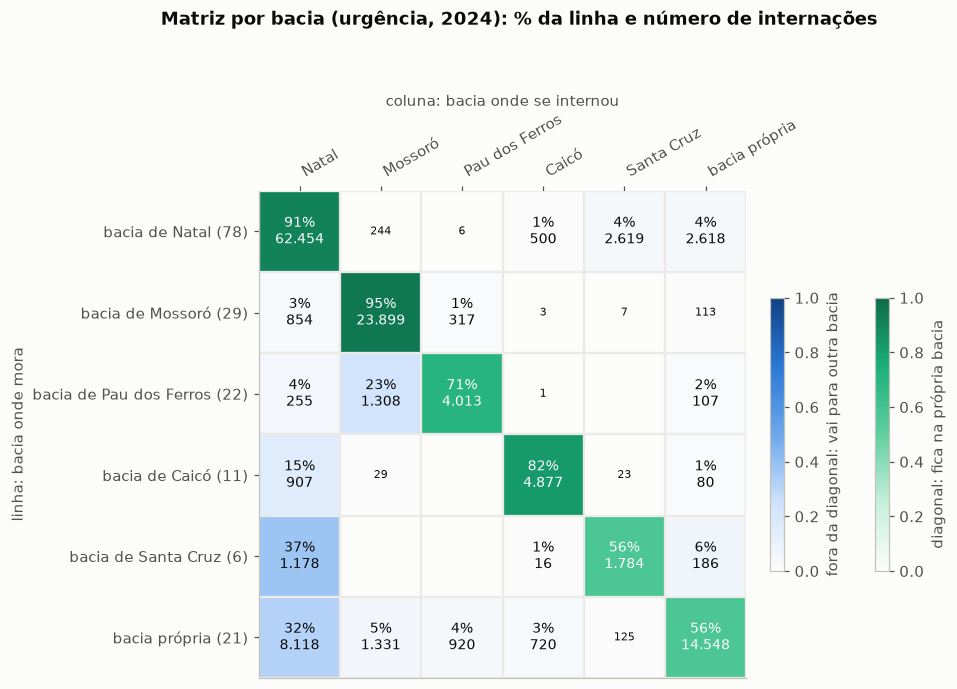

In [15]:
# soma dos blocos da matriz grande: cada bacia vira uma linha (onde mora) e uma coluna (onde se internou)
rotulo_grupo = [grupo[o] for o in ordem]
W_bacia = pd.DataFrame(W, index=rotulo_grupo, columns=rotulo_grupo)
W_bacia = W_bacia.T.groupby(level=0, sort=False).sum().T.groupby(level=0, sort=False).sum()
F_bacia = W_bacia.div(W_bacia.sum(axis=1), axis=0)  # cada linha soma 1

fig, ax = plt.subplots(figsize=(8.5, 7.2))
fora, dentro = desenhar(ax, F_bacia.to_numpy())
for i in range(len(F_bacia)):
    for j in range(len(F_bacia)):
        f, w = F_bacia.iat[i, j], W_bacia.iat[i, j]
        if w:
            ax.text(j, i, f"{f:.0%}\n{milhar(w)}" if f >= 0.005 else milhar(w), ha="center", va="center",
                    fontsize=9 if f >= 0.005 else 7.5, color=FUNDO if f > 0.55 else TINTA)
grupos = list(W_bacia.index)
ax.set_yticks(range(len(grupos)), [f"{PROPRIA} ({tam_grupo[g]})" if g == PROPRIA else f"bacia de {nome[g]} ({tam_grupo[g]})"
                                    for g in grupos])
ax.set_xticks(range(len(grupos)), [PROPRIA if g == PROPRIA else nome[g] for g in grupos])
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.setp(ax.get_xticklabels(), rotation=30, ha="left")
ax.set_xticks(np.arange(-0.5, len(grupos)), minor=True)
ax.set_yticks(np.arange(-0.5, len(grupos)), minor=True)
ax.grid(which="minor", color="#ebeae6", lw=1.5)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("coluna: bacia onde se internou")
ax.set_ylabel("linha: bacia onde mora")
fig.colorbar(dentro, ax=ax, shrink=0.5, pad=0.02, label="diagonal: fica na própria bacia")
fig.colorbar(fora, ax=ax, shrink=0.5, pad=0.04, label="fora da diagonal: vai para outra bacia")
fig.suptitle(f"Matriz por bacia (urgência, {ANO}): % da linha e número de internações",
             x=0.02, y=0.99, ha="left", fontsize=12, fontweight="bold")
fig.subplots_adjust(top=0.8)
salvar(fig, "01_matriz_bacias.png")
plt.show()

**As bacias no mapa.** O mesmo resultado da BFS desenhado sobre o RN: cada seta liga um município ao lugar onde seus moradores mais se internam, e a cor é a bacia a que ele pertence. As bacias próprias, em cinza, não têm seta porque o município aponta para si mesmo.

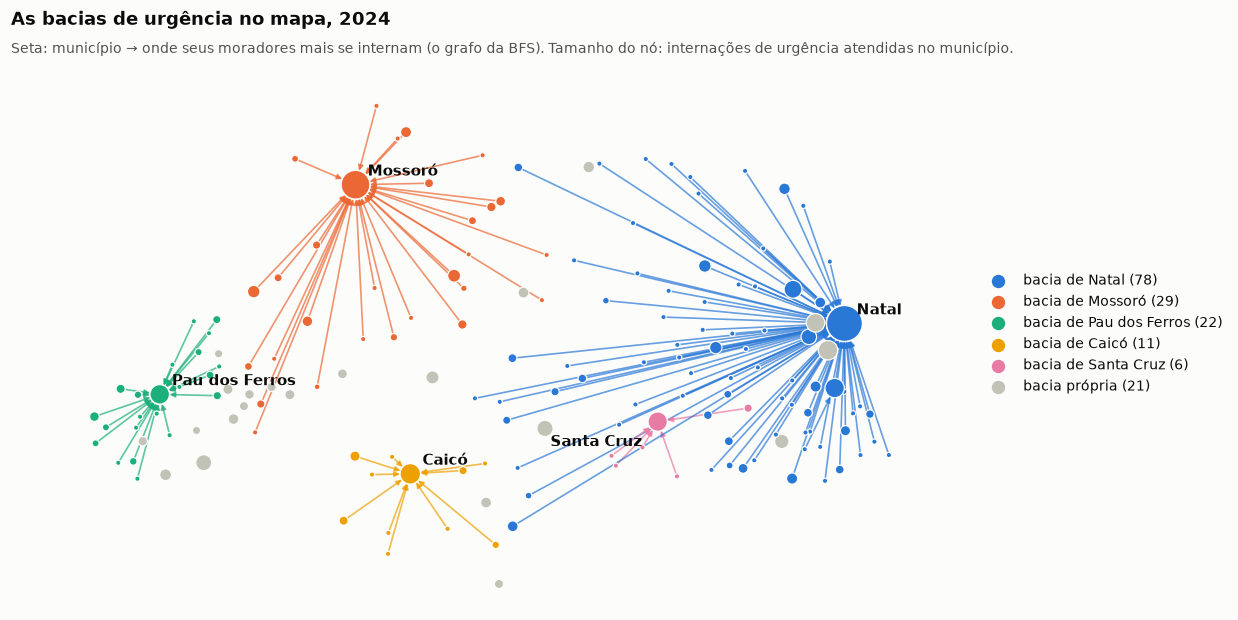

In [16]:
# cores categóricas em ordem fixa, uma por bacia grande; bacias próprias em cinza
CATEGORICAS = [AZUL, LARANJA, VERDE, "#eda100", "#e87ba4"]
grandes = [g for g in pd.unique(grupo[ordem]) if g != PROPRIA]
cor_bacia = {g: c for g, c in zip(grandes, CATEGORICAS)} | {PROPRIA: CINZA}
cor_no = [cor_bacia[grupo[o]] for o in aponta]
tamanho = [12 + 2.2 * np.sqrt(nos.at[o, "carga"]) for o in aponta]

fig, ax = plt.subplots(figsize=(12.5, 6.5))
# setas da BFS: cada município aponta para onde seus moradores mais se internam
setas = list(aponta.edges())
nx.draw_networkx_edges(aponta, pos, edgelist=setas, ax=ax, edge_color=[cor_bacia[grupo[o]] for o, _ in setas],
                       width=1.1, alpha=0.7, arrows=True, arrowstyle="-|>", arrowsize=7,
                       nodelist=list(aponta), node_size=tamanho)
nx.draw_networkx_nodes(aponta, pos, nodelist=list(aponta), node_size=tamanho, node_color=cor_no,
                       edgecolors=FUNDO, linewidths=0.8, ax=ax)
deslocamento = {"Santa Cruz": (-10, -16)}
for g in grandes:
    dx, dy = deslocamento.get(nome[g], (8, 6))
    ax.annotate(nome[g], pos[g], xytext=(dx, dy), textcoords="offset points", fontsize=10, fontweight="bold",
                color=TINTA, ha="right" if dx < 0 else "left")
for g in grandes:
    ax.scatter([], [], s=60, color=cor_bacia[g], label=f"bacia de {nome[g]} ({tam_grupo[g]})")
ax.scatter([], [], s=60, color=CINZA, label=f"{PROPRIA} ({tam_grupo[PROPRIA]})")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"As bacias de urgência no mapa, {ANO}", pad=22)
ax.text(0, 1.01, "Seta: município → onde seus moradores mais se internam (o grafo da BFS). "
        "Tamanho do nó: internações de urgência atendidas no município.", transform=ax.transAxes, fontsize=9,
        color=TINTA_2)
salvar(fig, "01_mapa_bacias.png")
plt.show()

**O que 1.4 mostra.**

- **Bacias são estrelas.** Na BFS, 140 dos 141 municípios que não são polo estão na camada 1: apontam direto para o polo. Só Várzea está na camada 2 (Várzea → São José de Mipibu → Natal). No mapa, cada bacia é uma estrela em volta do seu polo, e as bacias se separam por região: Mossoró no oeste, Pau dos Ferros no Alto Oeste, Caicó no Seridó, Santa Cruz no Trairi e Natal no leste.
- **Blocos = bacias.** Cada bacia aparece como uma coluna escura na borda esquerda do seu bloco: os municípios da bacia mandam quase tudo para o mesmo polo. As cinco bacias grandes (Natal 78, Mossoró 29, Pau dos Ferros 22, Caicó 11, Santa Cruz 6) cobrem 146 municípios.
- **Diagonal.** 83 dos 167 municípios têm a diagonal vazia. Nas bacias grandes a diagonal é clara: os municípios pequenos quase não se atendem. Nas 21 bacias próprias ela é verde-escura: a autossuficiência mediana é 52%, contra 0% a 11% nas bacias grandes.
- **Segundas opções.** Fora dos blocos aparecem as alternativas usadas na seção 5: a bacia de Pau dos Ferros também manda pacientes para Mossoró, e as de Caicó e de Santa Cruz também mandam para Natal. A hierarquia aparece na própria matriz: município pequeno → polo regional → Natal.
- **Por bacia.** A bacia de Mossoró atende 95% das próprias urgências, Natal 91% e Caicó 82%. Pau dos Ferros fica com 71% e manda 23% para Mossoró; Santa Cruz fica com só 56% e manda 37% para Natal. Pau dos Ferros e Santa Cruz são as bacias que mais dependem de outra bacia, e as bacias próprias mandam 32% para Natal.
- **Esparsidade.** A maior parte da matriz é branca: é a densidade de 0,039 da seção 1.2 vista como imagem.

## 2. Dependência de polo único

A seção 1 mostrou quem são os polos e como os municípios se agrupam em bacias. Esta seção responde à segunda parte da pergunta: **quanto o acesso de cada município depende de um único polo?**

**Dependência de polo único.** Para cada município, o destino principal é o que recebe mais internações de urgência dos seus residentes fora do município; a dependência é a fração das internações fora do município que vai para ele.

A diferença para a bacia (seção 1.4) é que aqui o próprio município não conta. Alexandria forma uma bacia própria, porque atende 84% das próprias urgências, mas metade do que sai de lá vai para Mossoró.

In [17]:
principal = {o: max(U.successors(o), key=lambda v: U[o][v]["weight"]) for o in U if U.out_degree(o) > 0}
nos["destino_principal"] = pd.Series(principal)
nos["dependencia"] = pd.Series({o: U[o][v]["weight"] for o, v in principal.items()}) / nos["forca_saida"]

print(f"Municípios que mandam ≥ 50% das urgências para um único polo: {(nos['dependencia'] >= 0.5).sum()}")
print(f"Municípios que mandam ≥ 70% das urgências para um único polo: {(nos['dependencia'] >= 0.7).sum()}")
nos["destino_principal"].map(nome).value_counts().head(8).rename("municípios que têm esse polo como destino principal")

Municípios que mandam ≥ 50% das urgências para um único polo: 129
Municípios que mandam ≥ 70% das urgências para um único polo: 65


destino_principal
Natal                 84
Mossoró               37
Pau dos Ferros        26
Caicó                 13
Santa Cruz             5
Parnamirim             1
São José de Mipibu     1
Name: municípios que têm esse polo como destino principal, dtype: int64

**O que a seção mostra.**

- **Dependência.** 129 municípios mandam mais da metade das urgências que saem do município para um único polo, e 65 mandam mais de 70%. Para os 83 municípios sem nenhuma internação de urgência no próprio município (seção 1.3), essa dependência vale para todo o atendimento de urgência, e não só para o que sai.
- **Poucos polos.** Os destinos principais se concentram em Natal (84 municípios), Mossoró (37), Pau dos Ferros (26), Caicó (13) e Santa Cruz (5): os mesmos polos das bacias da seção 1.4.

## 3. Componentes: a rede continua ligada se um polo parar?

*Semana 4 · `lesson05` e `practice`: componentes conexas, GCC, WCC e SCC.*

Primeiro vêm as componentes da rede original (3.1) e, depois, o que acontece com elas quando cada polo é removido (3.2).

### 3.1 Componentes: WCC, SCC e GCC

- **Componente conexa:** grupo de nós que se alcançam pelas arestas. A maior delas é a **GCC** (*giant connected component*).
- **Componente fraca (WCC):** ignora a direção. Diz se a rede é um bloco só.
- **Componente forte (SCC):** exige caminho de ida e de volta. Na nossa rede, uma SCC é um grupo de municípios que trocam pacientes nos dois sentidos, direta ou indiretamente.

In [18]:
print("Fracamente conexa?", nx.is_weakly_connected(U))
wcc = sorted(nx.weakly_connected_components(U), key=len, reverse=True)
print(f"WCCs: {len(wcc)}; a maior (a GCC da rede sem direção) tem {len(wcc[0])} municípios")
print("Fortemente conexa?", nx.is_strongly_connected(U))
scc = sorted(nx.strongly_connected_components(U), key=len, reverse=True)
print(f"SCCs: {len(scc)}; a maior tem {len(scc[0])} municípios; {sum(len(c) == 1 for c in scc)} são municípios sozinhos")
for c in scc[1:]:
    if len(c) > 1:
        print(f"Outra SCC com mais de um município: {', '.join(sorted(nome[m] for m in c))}")

nos["na_maior_scc"] = nos.index.isin(scc[0])
print(f"\nNa maior SCC (trocam pacientes nos dois sentidos, direta ou indiretamente):")
print(", ".join(sorted(nos.loc[nos["na_maior_scc"], "nome"])))
print("\nRecebem pacientes de outros municípios, mas estão fora da maior SCC:")
print(", ".join(sorted(nos.loc[~nos["na_maior_scc"] & recebe, "nome"])))

Fracamente conexa? True
WCCs: 1; a maior (a GCC da rede sem direção) tem 167 municípios
Fortemente conexa? False
SCCs: 129; a maior tem 38 municípios; 127 são municípios sozinhos
Outra SCC com mais de um município: Doutor Severiano, José da Penha

Na maior SCC (trocam pacientes nos dois sentidos, direta ou indiretamente):
Alexandria, Almino Afonso, Angicos, Antônio Martins, Apodi, Assú, Brejinho, Caicó, Ceará-Mirim, Cerro Corá, Currais Novos, Encanto, Extremoz, Frutuoso Gomes, Guamaré, Janduís, Januário Cicco, Jardim de Piranhas, João Câmara, Lagoa Nova, Lucrécia, Macaíba, Monte Alegre, Mossoró, Natal, Nova Cruz, Parnamirim, Pau dos Ferros, Pilões, Rafael Godeiro, Santa Cruz, Santo Antônio, São Gonçalo do Amarante, São José de Mipibu, São Paulo do Potengi, Tenente Ananias, Tibau do Sul, Touros

Recebem pacientes de outros municípios, mas estão fora da maior SCC:
Alto do Rodrigues, Caraúbas, Doutor Severiano, Governador Dix-Sept Rosado, Jardim do Seridó, José da Penha, Martins, Parelhas

**A maior SCC no mapa.** Só os 38 municípios da maior componente forte e os pares entre eles que trocam pacientes nos dois sentidos. As ligações de mão única dentro da SCC (173) ficam de fora, para o desenho não virar uma nuvem. Alguns municípios não têm nenhum par de ida e volta: estão na SCC por um ciclo indireto (A → B → C → A).

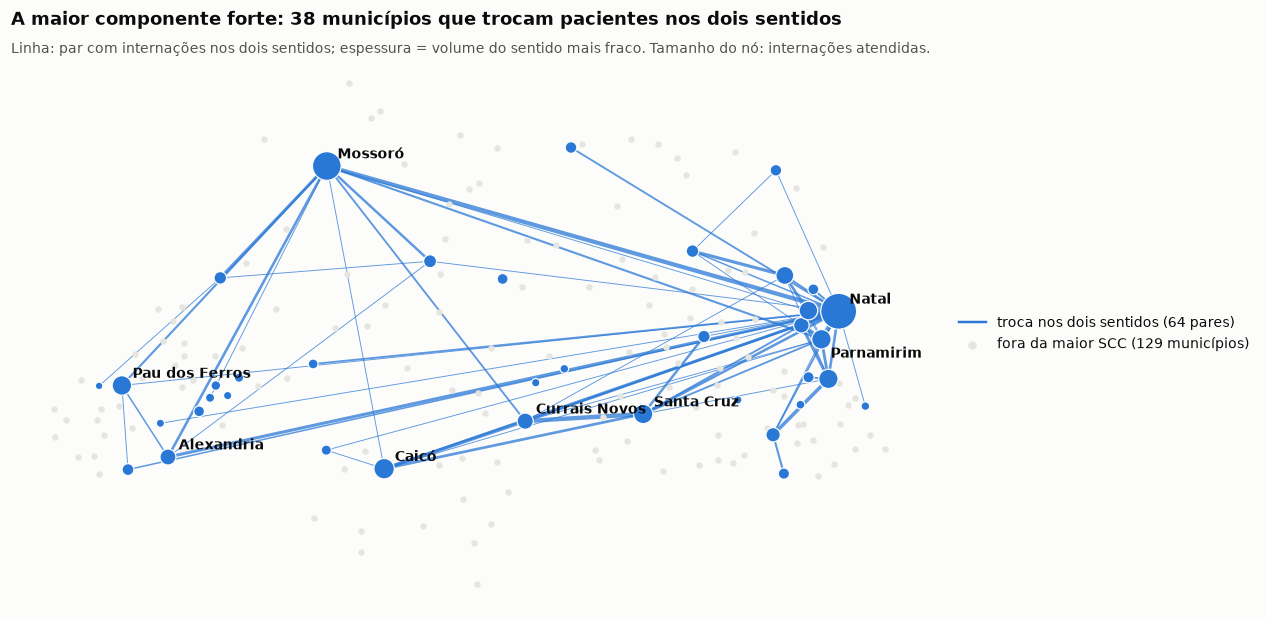

Ligações dentro da maior SCC: 301, sendo 64 pares de ida e volta
Internações nessas ligações: 44% das internações entre municípios
Pares com mais troca nos dois sentidos (sentido mais fraco):
  Parnamirim <-> Natal: 3242 e 76
  Macaíba <-> Natal: 1808 e 73
  Parnamirim <-> Macaíba: 60 e 100
  Currais Novos <-> Santa Cruz: 56 e 110
  Natal <-> São Gonçalo do Amarante: 48 e 2425
  Mossoró <-> Natal: 212 e 44


In [19]:
S = U.subgraph(scc[0])
# pares com ida e volta: é a troca nos dois sentidos que mantém a SCC
pares = {tuple(sorted((o, v))) for o, v in S.edges() if S.has_edge(v, o)}
fraco = {(o, v): min(S[o][v]["weight"], S[v][o]["weight"]) for o, v in pares}  # volume do sentido mais fraco
fora = [o for o in U if o not in S]
tamanho_scc = [12 + 2.2 * np.sqrt(nos.at[o, "carga"]) for o in S]

fig, ax = plt.subplots(figsize=(12, 6.5))
nx.draw_networkx_nodes(U, pos, nodelist=fora, node_size=10, node_color="#e6e5e0", ax=ax)
nx.draw_networkx_edges(S.to_undirected(), pos, edgelist=list(fraco), ax=ax, edge_color=AZUL, alpha=0.75,
                       width=[0.6 + 1.3 * np.log10(w) for w in fraco.values()])
nx.draw_networkx_nodes(S, pos, nodelist=list(S), node_size=tamanho_scc, node_color=AZUL, edgecolors=FUNDO,
                       linewidths=0.8, ax=ax)
deslocamento = {"Parnamirim": (6, -12)}
for cidade in ["Natal", "Mossoró", "Pau dos Ferros", "Caicó", "Santa Cruz", "Currais Novos", "Alexandria", "Parnamirim"]:
    dx, dy = deslocamento.get(cidade, (7, 5))
    ax.annotate(cidade, pos[cod[cidade]], xytext=(dx, dy), textcoords="offset points", fontsize=9, fontweight="bold",
                color=TINTA, ha="right" if dx < 0 else "left")
ax.plot([], [], color=AZUL, lw=1.6, label=f"troca nos dois sentidos ({len(pares)} pares)")
ax.scatter([], [], s=20, color="#e6e5e0", label=f"fora da maior SCC ({len(fora)} municípios)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"A maior componente forte: {len(S)} municípios que trocam pacientes nos dois sentidos", pad=22)
ax.text(0, 1.01, "Linha: par com internações nos dois sentidos; espessura = volume do sentido mais fraco. "
        "Tamanho do nó: internações atendidas.", transform=ax.transAxes, fontsize=9, color=TINTA_2)
salvar(fig, "03_maior_scc.png")
plt.show()

print(f"Ligações dentro da maior SCC: {S.number_of_edges()}, sendo {len(pares)} pares de ida e volta")
print(f"Internações nessas ligações: {S.size(weight='weight') / U.size(weight='weight'):.0%} das internações entre municípios")
mais_fortes = sorted(fraco.items(), key=lambda kv: kv[1], reverse=True)[:6]
print("Pares com mais troca nos dois sentidos (sentido mais fraco):")
for (o, v), w in mais_fortes:
    print(f"  {nome[o]} <-> {nome[v]}: {U[o][v]['weight']} e {U[v][o]['weight']}")

**O que 3.1 mostra.**

- **Um bloco só, sem direção.** A rede é fracamente conexa: uma única WCC com os 167 municípios, que é também a GCC da rede sem direção.
- **Pouca troca nos dois sentidos.** Há 129 SCCs: uma com 38 municípios, um par (Doutor Severiano e José da Penha, que trocam pacientes entre si) e 127 municípios sozinhos. A maior SCC reúne os polos (Natal, Mossoró, Pau dos Ferros, Caicó, Santa Cruz...) e os municípios que trocam pacientes com eles. Os 127 sozinhos só enviam: o fluxo vai para os polos e não volta.
- **A SCC liga as bacias.** No mapa, os pares de ida e volta ligam os polos regionais a Natal (Mossoró, Caicó, Pau dos Ferros, Santa Cruz) e entre si (Currais Novos ↔ Santa Cruz), além da região metropolitana (Parnamirim ↔ Natal: 3.242 internações num sentido e 76 no outro). As ligações dentro da SCC carregam 44% das internações entre municípios.
- **Polos locais fora da troca.** 14 municípios recebem pacientes de vizinhos (Caraúbas, Martins, Parelhas...), mas ficam fora da maior SCC: nenhum polo manda pacientes de volta para eles. São polos locais pendurados na hierarquia.

### 3.2 Remoção de polos: a rede continua ligada?

Para cada um dos 8 maiores polos: remover o polo e recalcular a maior WCC, o número de WCCs, os municípios isolados e a maior SCC. A remoção é feita em duas versões da rede:

- **rede completa:** todas as ligações, mesmo as de 1 internação no ano;
- **rotas estabelecidas:** só as ligações com pelo menos `LIMIAR` internações no ano (perto de uma por mês). Uma ligação de 1 internação no ano não é uma alternativa real de atendimento.

In [20]:
def acima_do_limiar(G, limiar):
    """Mesma rede, só com as ligações de pelo menos `limiar` internações no ano."""
    H = nx.DiGraph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from((o, v, d) for o, v, d in G.edges(data=True) if d["weight"] >= limiar)
    return H

def componentes(G):
    wcc = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
    return {
        "maior WCC": len(wcc[0]),
        "nº de WCCs": len(wcc),
        "isolados": sum(len(c) == 1 for c in wcc),
        "maior SCC": max(len(c) for c in nx.strongly_connected_components(G)),
        "fora da maior WCC": ", ".join(sorted(nome[c] for comp in wcc[1:] for c in comp)),
    }

redes = {"rede completa": U, f"rotas estabelecidas (≥ {LIMIAR}/ano)": acima_do_limiar(U, LIMIAR)}
remover = nos["forca_entrada"].nlargest(8).index
linhas = []
for rede, G in redes.items():
    linhas.append({"rede": rede, "cenário": "original", **componentes(G)})
    for polo in remover:
        H = G.copy()
        H.remove_node(polo)
        linhas.append({"rede": rede, "cenário": f"sem {nome[polo]}", **componentes(H)})
dano = pd.DataFrame(linhas).set_index(["rede", "cenário"])
dano

maior WCC  nº de WCCs  \
rede                           cenário                                         
rede completa                  original                      167           1   
                               sem Natal                     166           1   
                               sem Mossoró                   166           1   
                               sem São José de Mipibu        166           1   
                               sem Pau dos Ferros            166           1   
                               sem Santa Cruz                166           1   
                               sem Caicó                     166           1   
                               sem Ceará-Mirim               166           1   
                               sem Currais Novos             166           1   
rotas estabelecidas (≥ 10/ano) original                      167           1   
                               sem Natal                     165           2   
                               sem Mossoró                   161           6   
                               sem São José de Mipibu        166           1   
                               sem Pau dos Ferros            165           2   
                               sem Santa Cruz                166           1   
                               sem Caicó                     165           2   
                               sem Ceará-Mirim               166           1   
                               sem Currais Novos             166           1   

                                                       isolados  maior SCC  \
rede                           cenário                                       
rede completa                  original                       0         38   
                               sem Natal                      0         35   
                               sem Mossoró                    0         36   
                               sem São José de Mipibu         0         36   
                               sem Pau dos Ferros             0         37   
                               sem Santa Cruz                 0         37   
                               sem Caicó                      0         37   
                               sem Ceará-Mirim                0         35   
                               sem Currais Novos              0         37   
rotas estabelecidas (≥ 10/ano) original                       0         13   
                               sem Natal                      1          5   
                               sem Mossoró                    5         11   
                               sem São José de Mipibu         0          8   
                               sem Pau dos Ferros             1         12   
                               sem Santa Cruz                 0         10   
                               sem Caicó                      1         12   
                               sem Ceará-Mirim                0         13   
                               sem Currais Novos              0         11   

                                                                                       fora da maior WCC  
rede                           cenário                                                                    
rede completa                  original                                                                   
                               sem Natal                                                                  
                               sem Mossoró                                                                
                               sem São José de Mipibu                                                     
                               sem Pau dos Ferros                                                         
                               sem Santa Cruz                                                             
                               sem Ca

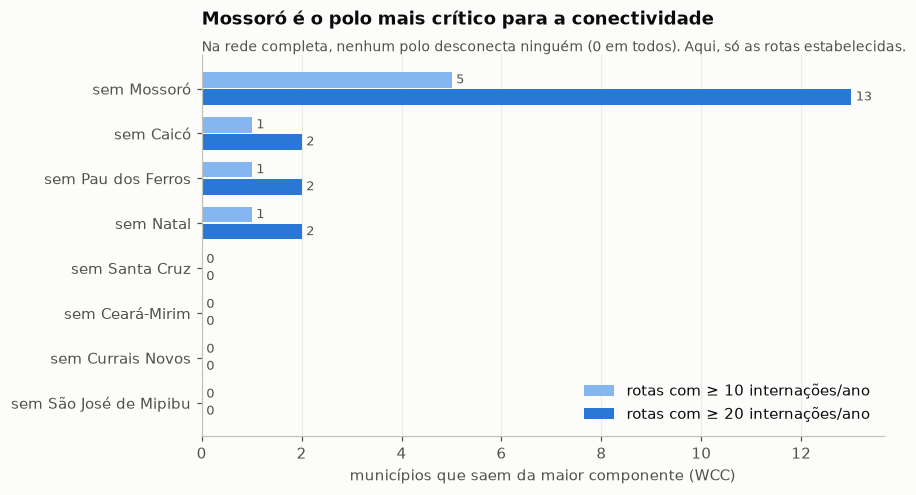

In [21]:
# quantos municípios saem da maior componente quando cada polo para, com dois limiares de rota estabelecida
limiares = {LIMIAR: "#86b6ef", 2 * LIMIAR: AZUL}

def saem_da_maior(G, polo):
    H = G.copy()
    H.remove_node(polo)
    return len(H) - componentes(H)["maior WCC"]

saem = pd.DataFrame({lim: {nome[p]: saem_da_maior(acima_do_limiar(U, lim), p) for p in remover}
                     for lim in limiares}).sort_values(2 * LIMIAR)

fig, ax = plt.subplots(figsize=(8, 4.5))
y, h = np.arange(len(saem)), 0.38
for k, (lim, cor) in enumerate(limiares.items()):
    ax.barh(y + (0.5 - k) * h, saem[lim], height=h - 0.04, color=cor, label=f"rotas com ≥ {lim} internações/ano")
    for yi, v in zip(y, saem[lim]):
        ax.annotate(str(v), (v, yi + (0.5 - k) * h), xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=TINTA_2)
ax.set_yticks(y, [f"sem {m}" for m in saem.index])
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("municípios que saem da maior componente (WCC)")
ax.set_title("Mossoró é o polo mais crítico para a conectividade", pad=20)
ax.text(0, 1.01, "Na rede completa, nenhum polo desconecta ninguém (0 em todos). Aqui, só as rotas estabelecidas.",
        transform=ax.transAxes, fontsize=9, color=TINTA_2)
ax.legend(frameon=False, loc="lower right")
salvar(fig, "03_remocao_componentes.png")
plt.show()

**O que 3.2 mostra.**

- **Na rede completa, nenhum polo desconecta ninguém.** Removendo qualquer um dos 8 maiores polos, os outros 166 municípios continuam numa só WCC: quase todo município manda pelo menos um paciente para vários lugares.
- **Com rotas estabelecidas, aparece o dano.** Sem Mossoró, 5 municípios ficam isolados (Governador Dix-Sept Rosado, Janduís, Paraú, Tibau e Triunfo Potiguar). Sem Natal, Pau dos Ferros ou Caicó, fica isolado 1 município em cada caso (Galinhos, Viçosa e Ipueira). Com rotas de pelo menos 20 internações, Mossoró isola 13.
- **Natal é o maior polo, mas Mossoró é o mais crítico para a conectividade.** Os municípios da bacia de Natal têm alternativas estabelecidas perto, na região metropolitana; os do entorno de Mossoró, não.
- **A troca nos dois sentidos passa por Natal.** Com rotas estabelecidas, a maior SCC cai de 13 para 5 municípios sem Natal.


## 4. Centralidades: quem parece importante?

*Semana 4 · `lesson06` e `hubs`: grau, closeness, betweenness, distribuições de centralidade (ECDF) e "vale a pena proteger os hubs?".*

A seção 3 mostrou quem, removido, desconecta municípios. Esta seção olha pelo outro lado: **pelas centralidades, quem parece importante?**

| medida | pergunta | no SUS/RN |
|---|---|---|
| grau de entrada | de quantos municípios diferentes recebe pacientes? | alcance do polo |
| força de entrada (*in-strength*), $s_i^{in} = \sum_j w_{ji}$ | quantas internações recebe? | volume do polo |
| grau de saída | para quantos destinos diferentes os moradores vão? | opções do município |
| closeness | quão perto está de quem manda pacientes? | polo acessível |
| betweenness | fica nos caminhos mais curtos entre grupos? | ponte estrutural |


In [22]:
nos["closeness"] = pd.Series(nx.closeness_centrality(U, distance="dist"))
nos["betweenness"] = pd.Series(nx.betweenness_centrality(U, weight="dist"))
medidas = {"grau_entrada": "grau de entrada", "forca_entrada": "força de entrada", "grau_saida": "grau de saída",
           "closeness": "closeness", "betweenness": "betweenness"}
pd.DataFrame({rotulo: nome[nos[col].nlargest(10).index].values for col, rotulo in medidas.items()},
             index=pd.RangeIndex(1, 11, name="posição"))

,grau de entrada,força de entrada,grau de saída,closeness,betweenness
posição,,,,,
1,Natal,Natal,Natal,Natal,Natal
2,Mossoró,Mossoró,Parnamirim,Mossoró,Mossoró
3,Santa Cruz,São José de Mipibu,Ceará-Mirim,Parnamirim,Macaíba
4,Currais Novos,Pau dos Ferros,Macau,Macaíba,São José de Mipibu
5,Parnamirim,Santa Cruz,Extremoz,São Gonçalo do Amarante,Pau dos Ferros
6,Macaíba,Caicó,João Câmara,São José de Mipibu,São Gonçalo do Amarante
7,Alexandria,Ceará-Mirim,Rio do Fogo,Pau dos Ferros,Parnamirim
8,São José de Mipibu,Currais Novos,Apodi,Santa Cruz,Ceará-Mirim
9,Pau dos Ferros,Macaíba,Mossoró,Alexandria,Caicó


### 4.1 Quem recebe mais pacientes? (força de entrada)

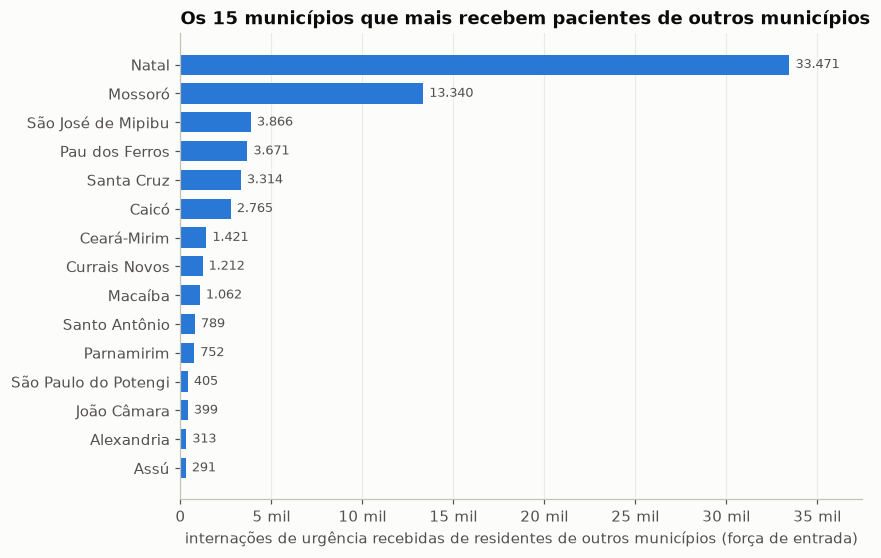

In [23]:
TOP_N = 15
t = nos.nlargest(TOP_N, "forca_entrada").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(t["nome"], t["forca_entrada"], height=0.7, color=AZUL)
for yi, v in enumerate(t["forca_entrada"]):
    ax.annotate(milhar(v), (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5,
                color=TINTA_2)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, t["forca_entrada"].max() * 1.12)
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:.0f} mil" if x else "0")
ax.set_xlabel("internações de urgência recebidas de residentes de outros municípios (força de entrada)")
ax.set_title(f"Os {TOP_N} municípios que mais recebem pacientes de outros municípios")
salvar(fig, "04_ranking_forca.png")
plt.show()

### 4.2 Alcance contra volume: grau de entrada × força de entrada

O grau de entrada diz **de quantos** municípios o polo recebe; a força de entrada, **quantas** internações. As linhas tracejadas marcam 10 e 100 internações por município de origem: acima da linha de 100, cada origem manda muitos pacientes; perto da linha de 10, o polo recebe de muitos lugares, mas pouco de cada.

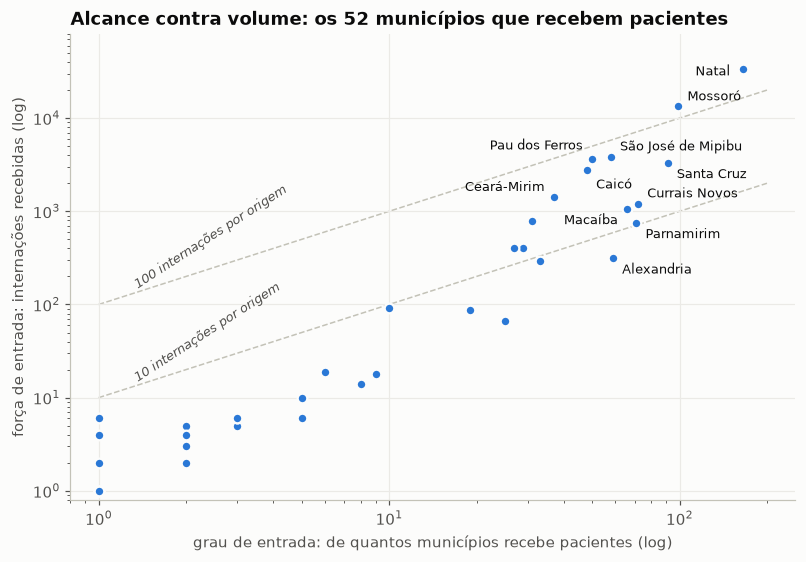

In [24]:
r = nos[recebe]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(r["grau_entrada"], r["forca_entrada"], s=40, color=AZUL, edgecolor=FUNDO, linewidth=1.5, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
# linhas de internações por origem: acima delas, cada município de origem manda muitos pacientes
xs = np.array([1, 200])
for por_origem in [10, 100]:
    ax.plot(xs, por_origem * xs, color=CINZA, lw=1, ls="--", zorder=1)
    ax.annotate(f"{por_origem} internações por origem", (1.3, por_origem * 1.3 * 1.15), fontsize=8.5,
                color=TINTA_2, style="italic", rotation=33)
deslocamento = {"Natal": (-8, -4), "Mossoró": (6, 4), "São José de Mipibu": (6, 4), "Pau dos Ferros": (-6, 6),
                "Caicó": (6, -12), "Santa Cruz": (6, -10), "Ceará-Mirim": (-6, 4), "Currais Novos": (6, 4),
                "Macaíba": (-6, -10), "Parnamirim": (6, -10), "Alexandria": (6, -10)}
for cidade, (dx, dy) in deslocamento.items():
    c = cod[cidade]
    ax.annotate(cidade, (r.at[c, "grau_entrada"], r.at[c, "forca_entrada"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5, color=TINTA, ha="right" if dx < 0 else "left")
ax.set_xlim(0.8, 250)
ax.set_ylim(0.8, 80_000)
ax.set_xlabel("grau de entrada: de quantos municípios recebe pacientes (log)")
ax.set_ylabel("força de entrada: internações recebidas (log)")
ax.set_title(f"Alcance contra volume: os {len(r)} municípios que recebem pacientes")
salvar(fig, "04_grau_forca.png")
plt.show()

### 4.3 Para quantos destinos cada município manda pacientes? (grau de saída)

Um grau de saída alto não quer dizer independência: o município pode mandar pacientes para muitos lugares e, ainda assim, quase todos para um só. Por isso o gráfico mostra, ao lado, a dependência da seção 2 (a fração do que sai do município que vai para o destino principal).

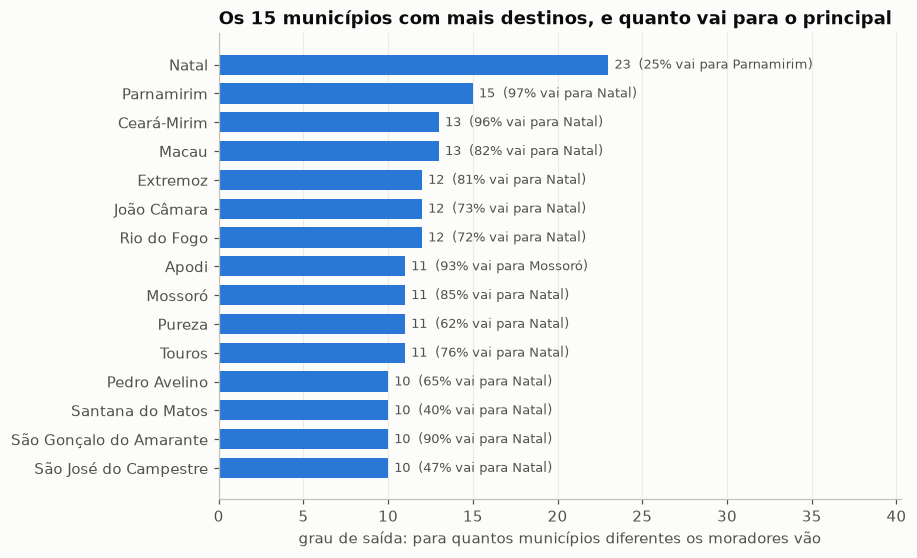

In [25]:
t = nos.nlargest(TOP_N, "grau_saida").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(t["nome"], t["grau_saida"], height=0.7, color=AZUL)
for yi, (_, linha) in enumerate(t.iterrows()):
    principal_nome = nome[linha["destino_principal"]]
    ax.annotate(f"{linha['grau_saida']}  ({linha['dependencia']:.0%} vai para {principal_nome})",
                (linha["grau_saida"], yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5,
                color=TINTA_2)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, t["grau_saida"].max() * 1.75)
ax.set_xlabel("grau de saída: para quantos municípios diferentes os moradores vão")
ax.set_title(f"Os {TOP_N} municípios com mais destinos, e quanto vai para o principal")
salvar(fig, "04_ranking_grau_saida.png")
plt.show()

### 4.4 Quem é central e quem é ponte? (closeness × betweenness)

*Como no `hubs` §6.3 ("hub é a mesma coisa que intermediário?").* As linhas tracejadas são as médias dos 52 municípios que recebem pacientes e dividem o gráfico em quatro perfis: **central** (perto de quem manda pacientes), **ponte** (nos caminhos mais curtos entre grupos), os dois ao mesmo tempo, ou nenhum (**periférico**).

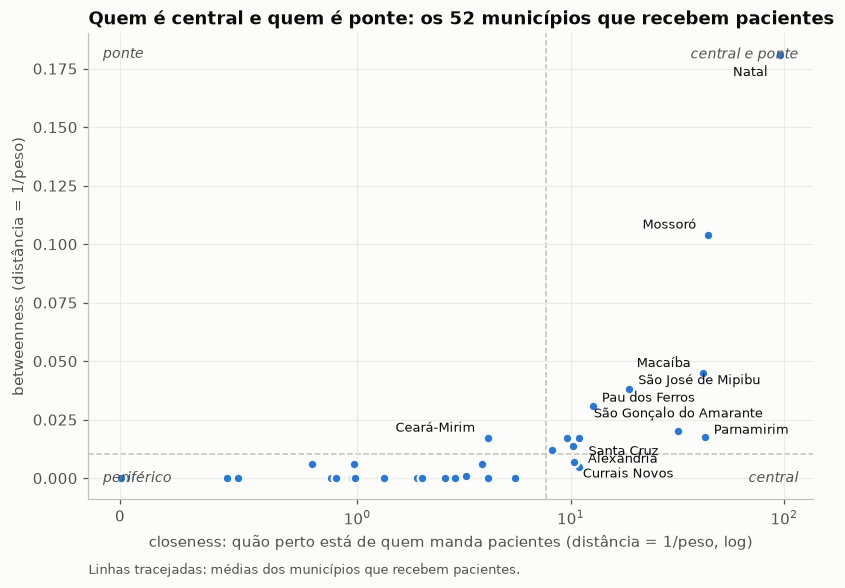

In [26]:
r = nos[recebe]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(r["closeness"], r["betweenness"], s=40, color=AZUL, edgecolor=FUNDO, linewidth=1.5, zorder=3)
ax.set_xscale("symlog", linthresh=1)
mx, my = r["closeness"].mean(), r["betweenness"].mean()  # cortes: médias dos municípios que recebem
ax.axvline(mx, color=CINZA, lw=1, ls="--", zorder=1)
ax.axhline(my, color=CINZA, lw=1, ls="--", zorder=1)
quadrantes = [(0.98, 0.97, "central e ponte", "right", "top"), (0.02, 0.97, "ponte", "left", "top"),
              (0.98, 0.03, "central", "right", "bottom"), (0.02, 0.03, "periférico", "left", "bottom")]
for x, y, texto, ha, va in quadrantes:
    ax.text(x, y, texto, transform=ax.transAxes, ha=ha, va=va, fontsize=9, color=TINTA_2, style="italic")
deslocamento = {"Natal": (-8, -14), "Mossoró": (-8, 4), "Macaíba": (-8, 4), "Parnamirim": (6, 2),
                "São Gonçalo do Amarante": (0, 9), "São José de Mipibu": (6, 3), "Pau dos Ferros": (6, 3),
                "Ceará-Mirim": (-8, 4), "Currais Novos": (6, -10), "Alexandria": (6, 3), "Santa Cruz": (6, -11)}
for cidade, (dx, dy) in deslocamento.items():
    c = cod[cidade]
    ax.annotate(cidade, (r.at[c, "closeness"], r.at[c, "betweenness"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5, color=TINTA,
                ha="center" if dx == 0 else ("right" if dx < 0 else "left"))
ax.set_xlabel("closeness: quão perto está de quem manda pacientes (distância = 1/peso, log)")
ax.set_ylabel("betweenness (distância = 1/peso)")
ax.set_title(f"Quem é central e quem é ponte: os {len(r)} municípios que recebem pacientes")
ax.text(0, -0.16, "Linhas tracejadas: médias dos municípios que recebem pacientes.", transform=ax.transAxes,
        fontsize=8.5, color=TINTA_2)
salvar(fig, "04_closeness_betweenness.png")
plt.show()

### 4.5 A rede é concentrada em poucos municípios? (ECDF)

*Como no `hubs` §5.3.* A ECDF mostra, para cada valor *x*, a fração dos municípios com valor até *x*. A seção 1.3 mostrou a distribuição de grau em histograma; aqui as quatro centralidades aparecem na mesma forma, para comparar.

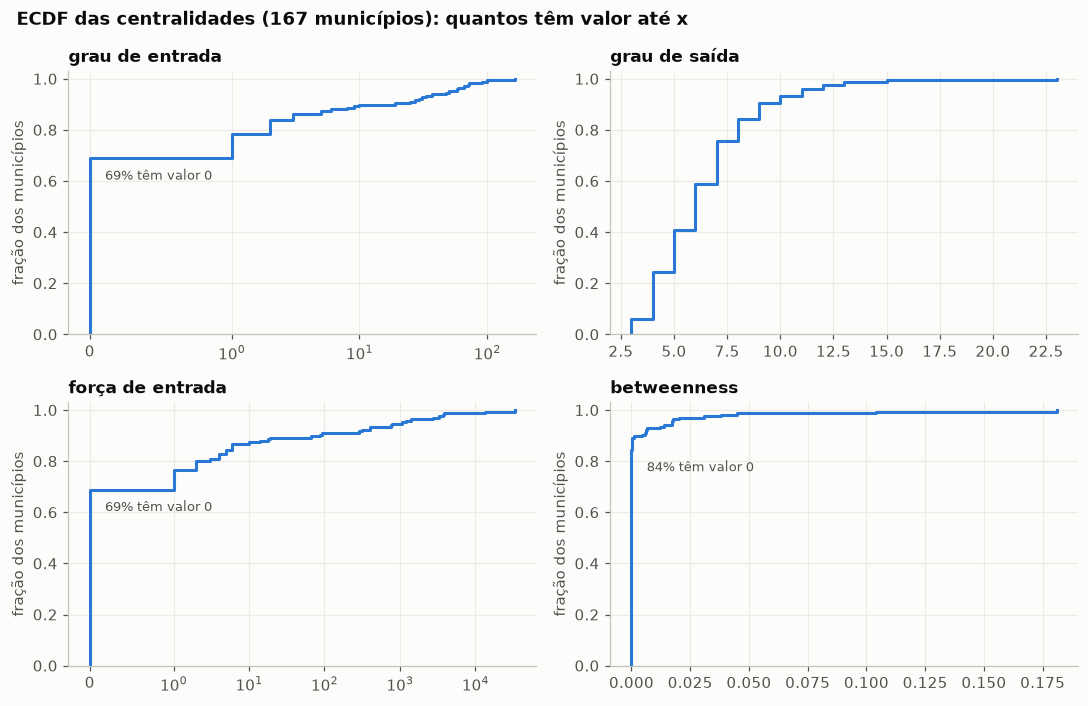

In [27]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, (col, rotulo) in zip(axs.flat, [("grau_entrada", "grau de entrada"), ("grau_saida", "grau de saída"),
                                         ("forca_entrada", "força de entrada"), ("betweenness", "betweenness")]):
    x = np.sort(nos[col].to_numpy())
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=AZUL, lw=2)
    if col in ("forca_entrada", "grau_entrada"):
        ax.set_xscale("symlog", linthresh=1)
    zero = (nos[col] == 0).mean()
    if zero > 0:
        ax.annotate(f"{zero:.0%} têm valor 0", (0, zero), xytext=(10, -14), textcoords="offset points",
                    fontsize=8.5, color=TINTA_2)
    ax.set_ylim(0, 1.03)
    ax.set_title(rotulo, fontsize=11)
    ax.set_ylabel("fração dos municípios")
fig.suptitle(f"ECDF das centralidades ({len(nos)} municípios): quantos têm valor até x",
             x=0.02, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
salvar(fig, "04_ecdf_centralidades.png")
plt.show()

### 4.6 Quem parece importante contra quem causa dano

*Como no `hubs` §7 ("vale a pena proteger os hubs?").* As centralidades apontam candidatos; a remoção da seção 3.2 testa se eles são críticos. A tabela mostra a posição de cada um dos 8 maiores polos em cada centralidade (1 = o maior) e quantos municípios ficam isolados sem ele.

In [28]:
# quem parece importante (posição em cada centralidade) contra quem desconecta municípios (seção 3.2)
posicao = nos[list(medidas)].rank(ascending=False, method="min").astype(int).rename(columns=medidas)
comparacao = posicao.loc[remover].set_index(nos.loc[remover, "nome"])
for lim in saem.columns:
    comparacao[f"isolados sem ele (rotas ≥ {lim})"] = saem[lim]
comparacao.sort_values(f"isolados sem ele (rotas ≥ {2 * LIMIAR})", ascending=False)

,grau de entrada,força de entrada,grau de saída,closeness,betweenness,isolados sem ele (rotas ≥ 10),isolados sem ele (rotas ≥ 20)
nome,,,,,,,
Mossoró,2,2,8,2,2,5,13
Natal,1,1,1,1,1,1,2
Pau dos Ferros,9,4,100,7,5,1,2
Caicó,10,6,42,12,9,1,2
São José de Mipibu,8,3,17,6,4,0,0
Santa Cruz,3,5,27,8,10,0,0
Ceará-Mirim,11,7,3,15,8,0,0
Currais Novos,4,8,42,10,13,0,0


**O que a seção mostra.**

- **Volume (4.1).** Natal recebe 33.471 internações de urgência de outros municípios, Mossoró 13.340. Depois vêm São José de Mipibu, Pau dos Ferros, Santa Cruz e Caicó, entre 2.700 e 3.900 cada.
- **Alcance contra volume (4.2).** Natal (cerca de 200 internações por origem) e Mossoró (135) estão acima da linha de 100: recebem de muitos municípios e muitos pacientes de cada. Os polos regionais (Pau dos Ferros, São José de Mipibu, Caicó, Santa Cruz) ficam entre 36 e 73 por origem. Parnamirim, Currais Novos, Macaíba e Alexandria recebem de 59 a 72 municípios, mas só 5 a 17 pacientes de cada: alcance grande, volume pequeno.
- **Grau de saída não é independência (4.3).** Parnamirim manda pacientes para 15 destinos, mas 97% do que sai vai para Natal; Ceará-Mirim, para 13, com 96% para Natal. Natal tem o maior grau de saída (23), mas quase não manda ninguém: 98,9% das urgências dos moradores ficam em Natal.
- **Central e ponte (4.4).** Natal e Mossoró são centrais e pontes ao mesmo tempo, muito acima dos outros. Macaíba é a 3ª em betweenness, à frente dos polos regionais, por estar entre a grande Natal e o resto do estado. Ceará-Mirim aparece como ponte sem ser central. Currais Novos e Alexandria são centrais, mas não intermediam.
- **Concentração (4.5).** 69% dos municípios têm grau e força de entrada 0, e 84% têm betweenness 0. O grau de saída, ao contrário, fica entre 3 e 23 para todos. É a assinatura de muitos municípios pequenos e poucos hubs.
- **Centralidade não é o mesmo que dano (4.6).** Natal é o 1º em todas as centralidades, mas sem ele só 1 município fica sem rota estabelecida (2 com rotas de 20). Mossoró é o 2º e isola 5 (13). São José de Mipibu (3º em força de entrada) e Santa Cruz (3º em grau de entrada) não isolam ninguém. As centralidades apontam os candidatos; só a remoção mostra que **Mossoró é o mais crítico para a conectividade**, e a seção 5 mostra que **Natal é o mais crítico para a carga, nesse caso, a força de entrada**.

## 5. E se um polo parar?

*Semana 4 · `hubs` §7 ("vale a pena proteger os hubs?") e `practice` §8 ("quanto aguenta a rede antes de virar arquipélago?").*

A seção 3.2 removeu os polos e mediu as componentes: na rede completa ninguém fica desconectado, porque quase todo município manda algum paciente para vários lugares. O dano real aparece em três medidas:

1. **internações afetadas:** as que o polo recebia de fora mais as dos próprios residentes;
2. **sem alternativa:** internações de municípios que não têm nenhum outro destino;
3. **tempo de viagem:** tempo de carro (OSRM) da sede de origem até o novo destino.

**Hipótese de redistribuição.** Cada município divide as internações que iam para o polo entre os outros destinos que **já usa**, na proporção do volume atual. Exemplo: se Patu manda 60% para Mossoró e 40% para Natal, sem Mossoró tudo vai para Natal. Os residentes do próprio polo seguem a mesma regra com os destinos do polo. Na prática quem decide é a regulação estadual de leitos, então isso é um cenário, não uma previsão.

In [29]:
def cenario(G, P):
    """O polo P deixa de atender. Devolve (resumo, detalhe por origem, internações extras por destino)."""
    fontes = [(o, G[o][P]["weight"]) for o in G.predecessors(P)] + [(P, G.nodes[P]["locais"])]
    carga = pd.Series(nx.get_node_attributes(G, "locais")) + pd.Series(dict(G.in_degree(weight="weight")))
    extra = pd.Series(0.0, index=list(G))
    detalhe = []
    for o, w in fontes:
        alternativas = {v: G[o][v]["weight"] for v in G.successors(o) if v != P}
        total = sum(alternativas.values())
        for v, x in alternativas.items():
            extra[v] += w * x / total
        depois = sum(x / total * horas(o, v) for v, x in alternativas.items()) if alternativas else np.nan
        detalhe.append({"origem": o, "internacoes": w, "horas_antes": horas(o, P), "horas_depois": depois})
    detalhe = pd.DataFrame(detalhe).set_index("origem")

    de_fora = detalhe.drop(index=P)
    com_alt = de_fora[de_fora["horas_depois"].notna()]
    absorve = extra.idxmax()
    resumo = {
        "polo": nome[P],
        "afetadas": int(detalhe["internacoes"].sum()),
        "de outros municípios": int(de_fora["internacoes"].sum()),
        "municípios que enviam": len(de_fora),
        "sem alternativa": int(de_fora.loc[de_fora["horas_depois"].isna(), "internacoes"].sum()),
        "horas antes (de fora)": np.average(com_alt["horas_antes"], weights=com_alt["internacoes"]),
        "horas depois (de fora)": np.average(com_alt["horas_depois"], weights=com_alt["internacoes"]),
        "horas depois (residentes do polo)": detalhe.at[P, "horas_depois"],
        "quem mais absorve": nome[absorve],
        "carga extra em quem mais absorve": extra[absorve] / carga[absorve],
    }
    return resumo, detalhe, extra

U_rotas = acima_do_limiar(U, LIMIAR)
polos = nos["forca_entrada"].nlargest(8).index
cenarios = pd.DataFrame([cenario(U, P)[0] for P in polos]).set_index("polo")
cenarios.insert(4, f"sem rota estabelecida (≥ {LIMIAR}/ano)",
                [cenario(U_rotas, P)[0]["sem alternativa"] for P in polos])
cenarios.round(2)

,afetadas,de outros municípios,municípios que enviam,sem alternativa,sem rota estabelecida (≥ 10/ano),horas antes (de fora),horas depois (de fora),horas depois (residentes do polo),quem mais absorve,carga extra em quem mais absorve
polo,,,,,,,,,,
Natal,60007,33471,165,0,70,1.32,0.94,1.47,Macaíba,7.79
Mossoró,23940,13340,99,0,1214,1.35,2.76,4.06,Natal,0.27
São José de Mipibu,4506,3866,58,0,0,0.63,1.05,0.62,Natal,0.06
Pau dos Ferros,4678,3671,50,0,32,0.73,2.69,2.45,Mossoró,0.15
Santa Cruz,4495,3314,91,0,0,0.89,1.52,1.42,Natal,0.06
Caicó,5698,2765,48,0,70,0.84,3.06,3.50,Natal,0.08
Ceará-Mirim,3205,1421,37,0,0,1.11,1.58,0.60,Natal,0.05
Currais Novos,2094,1212,72,0,0,0.86,1.98,2.06,Natal,0.02


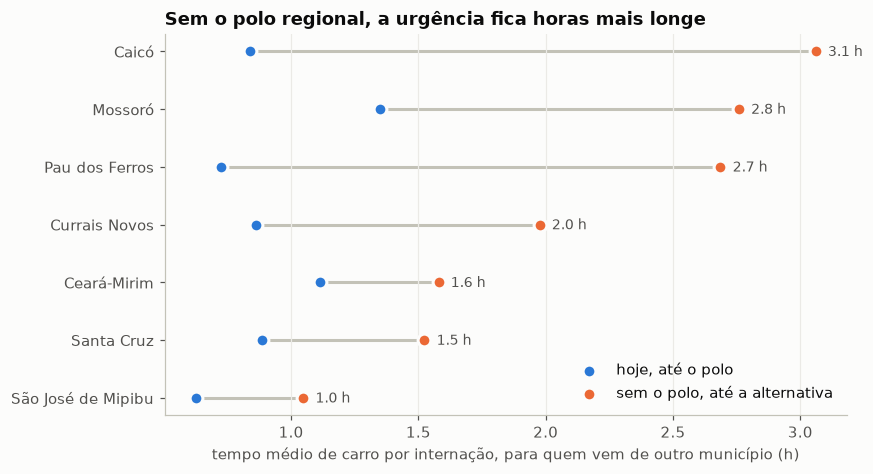

In [30]:
c = cenarios.drop(index="Natal").sort_values("horas depois (de fora)")  # Natal: ver texto, o problema é carga
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(c))
ax.hlines(y, c["horas antes (de fora)"], c["horas depois (de fora)"], color=CINZA, lw=2, zorder=1)
ax.scatter(c["horas antes (de fora)"], y, s=70, color=AZUL, edgecolor=FUNDO, linewidth=2, zorder=3,
           label="hoje, até o polo")
ax.scatter(c["horas depois (de fora)"], y, s=70, color=LARANJA, edgecolor=FUNDO, linewidth=2, zorder=3,
           label="sem o polo, até a alternativa")
for i, (_, r) in enumerate(c.iterrows()):
    ax.annotate(f"{r['horas depois (de fora)']:.1f} h", (r["horas depois (de fora)"], i),
                xytext=(8, -3), textcoords="offset points", fontsize=9, color=TINTA_2)
ax.set_yticks(y, c.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("tempo médio de carro por internação, para quem vem de outro município (h)")
ax.set_title("Sem o polo regional, a urgência fica horas mais longe")
ax.legend(frameon=False, loc="lower right")
salvar(fig, "05_tempo_sem_polo.png")
plt.show()

**Rota estabelecida.** Com todas as ligações, sempre existe alguma alternativa: basta um único paciente ter ido a outro lugar no ano. A coluna "sem rota estabelecida" refaz o cenário contando como alternativa só os destinos que recebem pelo menos `LIMIAR` internações por ano do município (perto de uma por mês), e conta as internações de quem fica sem nenhuma.

### 5.1 Detalhe: Mossoró para

Quais municípios mais perdem e para onde vão as internações.

In [31]:
_, detalhe, extra = cenario(U, cod["Mossoró"])
detalhe = detalhe.assign(municipio=detalhe.index.map(nome),
                         horas_a_mais=detalhe["horas_depois"] - detalhe["horas_antes"])
print("Para onde vão as internações:")
print((extra.nlargest(5) / extra.sum()).rename(index=nome).map("{:.0%}".format).to_string())
detalhe.sort_values("internacoes", ascending=False).head(12).set_index("municipio").round(2)

Para onde vão as internações:
Natal             67%
Pau dos Ferros    10%
Assú               9%
Apodi              6%
Alexandria         4%


,internacoes,horas_antes,horas_depois,horas_a_mais
municipio,,,,
Mossoró,10600,0.00,4.06,4.06
Assú,1377,1.19,3.21,2.02
Baraúna,1054,0.65,3.53,2.88
Apodi,907,1.00,3.86,2.86
Areia Branca,847,0.85,3.40,2.55
Caraúbas,623,1.20,2.55,1.35
Serra do Mel,500,0.73,3.87,3.14
Governador Dix-Sept Rosado,500,0.63,4.43,3.80
Alto do Rodrigues,426,1.69,2.16,0.47


### 5.2 Vulnerabilidade de cada município

Para cada município: se o seu **destino principal** parar, quanto tempo a mais os residentes viajam até a alternativa? É o mesmo cenário, aplicado do ponto de vista de quem envia.

In [32]:
vulnerabilidade = {}
for o, P in principal.items():
    alternativas = {v: U[o][v]["weight"] for v in U.successors(o) if v != P}
    total = sum(alternativas.values())
    depois = sum(x / total * horas(o, v) for v, x in alternativas.items()) if alternativas else np.nan
    vulnerabilidade[o] = {"horas_ate_principal": horas(o, P), "horas_sem_principal": depois}
nos = nos.join(pd.DataFrame(vulnerabilidade).T)
nos["horas_a_mais"] = nos["horas_sem_principal"] - nos["horas_ate_principal"]

print(f"Sem nenhuma alternativa: {nos['horas_sem_principal'].isna().sum()} municípios "
      f"{sorted(nos.loc[nos['horas_sem_principal'].isna() & nos['destino_principal'].notna(), 'nome'])}")
for h in [1, 2, 3]:
    print(f"Mais de {h} h a mais de viagem: {(nos['horas_a_mais'] > h).sum()} municípios")
print(f"Alternativa mais perto que o principal: {(nos['horas_a_mais'] < 0).sum()} municípios")
sem_rota = [o for o, P in principal.items() if not any(v != P for v in U_rotas.successors(o))]
nos["sem_rota_alternativa"] = nos.index.isin(sem_rota)
print()
print(f"Sem rota estabelecida (≥ {LIMIAR}/ano) além do destino principal: {len(sem_rota)} municípios")
for o in sorted(sem_rota, key=lambda o: nome[principal[o]]):
    print(f"  {nome[o]} (destino principal: {nome[principal[o]]}, {nos.at[o, 'dependencia']:.0%} das urgências)")
print()
(nos.groupby(nos["destino_principal"].map(nome))["horas_a_mais"]
    .agg(municipios="size", media_horas_a_mais="mean", pior="max")
    .sort_values("municipios", ascending=False).head(6).round(2))

Sem nenhuma alternativa: 0 municípios []
Mais de 1 h a mais de viagem: 54 municípios
Mais de 2 h a mais de viagem: 32 municípios
Mais de 3 h a mais de viagem: 15 municípios
Alternativa mais perto que o principal: 87 municípios

Sem rota estabelecida (≥ 10/ano) além do destino principal: 8 municípios
  Ipueira (destino principal: Caicó, 85% das urgências)
  Governador Dix-Sept Rosado (destino principal: Mossoró, 99% das urgências)
  Janduís (destino principal: Mossoró, 89% das urgências)
  Paraú (destino principal: Mossoró, 93% das urgências)
  Tibau (destino principal: Mossoró, 99% das urgências)
  Triunfo Potiguar (destino principal: Mossoró, 97% das urgências)
  Galinhos (destino principal: Natal, 76% das urgências)
  Viçosa (destino principal: Pau dos Ferros, 71% das urgências)



,municipios,media_horas_a_mais,pior
destino_principal,,,
Natal,84,-0.61,1.06
Mossoró,37,0.91,4.35
Pau dos Ferros,26,1.95,3.34
Caicó,13,2.55,3.45
Santa Cruz,5,1.19,1.41
Parnamirim,1,1.56,1.56


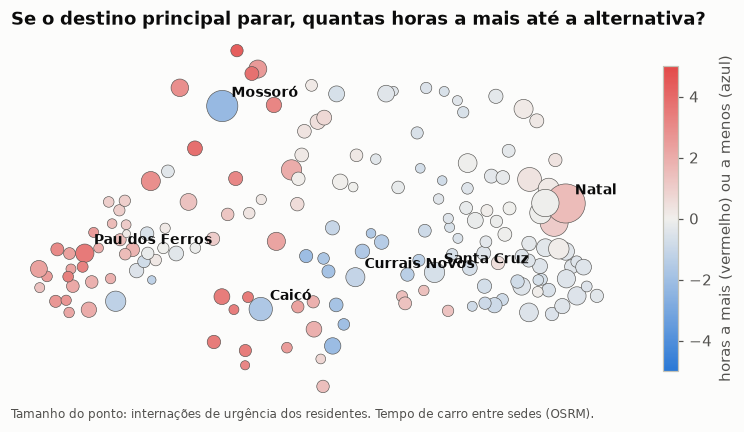

In [33]:
m = nos.join(coord).dropna(subset=["horas_a_mais"])
lim = np.ceil(m["horas_a_mais"].abs().max())
fig, ax = plt.subplots(figsize=(9, 6))
pts = ax.scatter(m["longitude"], m["latitude"], c=m["horas_a_mais"], cmap=DIVERGENTE,
                 norm=TwoSlopeNorm(0, -lim, lim), s=np.sqrt(m["residentes"]) * 4,
                 edgecolor=TINTA_2, linewidth=0.4, zorder=3)
for cidade in ["Natal", "Mossoró", "Pau dos Ferros", "Caicó", "Santa Cruz", "Currais Novos"]:
    c = coord.loc[cod[cidade]]
    ax.annotate(cidade, (c["longitude"], c["latitude"]), xytext=(6, 6), textcoords="offset points",
                fontsize=9, color=TINTA, fontweight="bold")
ax.set_aspect("equal")
ax.grid(False)
ax.set_xticks([]); ax.set_yticks([])
for lado in ["left", "bottom"]:
    ax.spines[lado].set_visible(False)
ax.set_title("Se o destino principal parar, quantas horas a mais até a alternativa?")
fig.colorbar(pts, ax=ax, shrink=0.6, label="horas a mais (vermelho) ou a menos (azul)")
ax.text(0, -0.04, "Tamanho do ponto: internações de urgência dos residentes. Tempo de carro entre sedes (OSRM).",
        transform=ax.transAxes, fontsize=8, color=TINTA_2)
salvar(fig, "05_mapa_vulnerabilidade.png")
plt.show()

### 5.3 Ataque dirigido contra falha aleatória

Agora o experimento do professor, na forma original: remover polos em sequência e medir a fração de municípios que continua na maior componente. A rede usada é o **esqueleto** com ligações de pelo menos `LIMIAR` internações por ano, sem direção (a seção 8 testa outros limiares). Comparamos quatro ordens de remoção: força de entrada, grau de entrada, betweenness e aleatória (média de 200 sorteios).

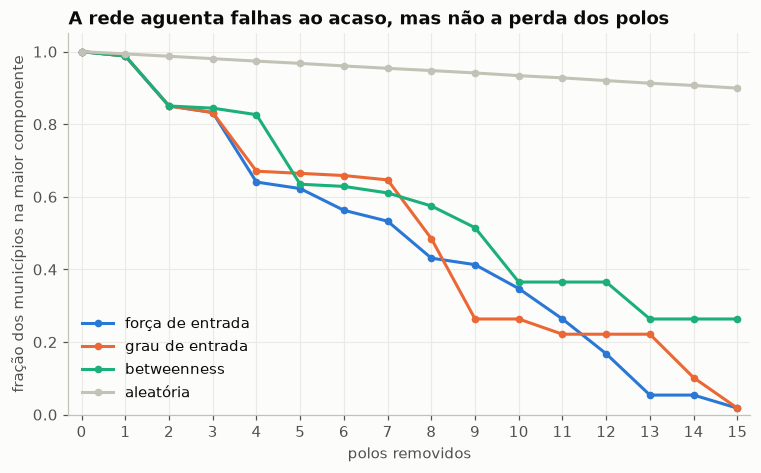

Ordem por força: ['Natal', 'Mossoró', 'São José de Mipibu', 'Pau dos Ferros', 'Santa Cruz', 'Caicó']


,força de entrada,grau de entrada,betweenness,aleatória
0,1.00,1.00,1.00,1.00
1,0.99,0.99,0.99,0.99
2,0.85,0.85,0.85,0.99
4,0.64,0.67,0.83,0.97
6,0.56,0.66,0.63,0.96
10,0.35,0.26,0.37,0.93
15,0.02,0.02,0.26,0.90


In [34]:
esqueleto = nx.Graph()
esqueleto.add_nodes_from(U)
esqueleto.add_edges_from((o, v) for o, v, d in U.edges(data=True) if d["weight"] >= LIMIAR)

def ataque(G, ordem, passos):
    H = G.copy()
    fracoes = [len(max(nx.connected_components(H), key=len)) / G.number_of_nodes()]
    for n in ordem[:passos]:
        H.remove_node(n)
        fracoes.append(len(max(nx.connected_components(H), key=len)) / G.number_of_nodes())
    return fracoes

PASSOS = 15
ordens = {
    "força de entrada": list(nos["forca_entrada"].sort_values(ascending=False).index),
    "grau de entrada": list(nos["grau_entrada"].sort_values(ascending=False).index),
    "betweenness": list(nos["betweenness"].sort_values(ascending=False).index),
}
curvas = {k: ataque(esqueleto, o, PASSOS) for k, o in ordens.items()}
rng = np.random.default_rng(SEMENTE)
curvas["aleatória"] = np.mean([ataque(esqueleto, list(rng.permutation(list(esqueleto))), PASSOS)
                               for _ in range(200)], axis=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
cores = {"força de entrada": AZUL, "grau de entrada": LARANJA, "betweenness": VERDE, "aleatória": CINZA}
for k, ys in curvas.items():
    ax.plot(range(PASSOS + 1), ys, color=cores[k], lw=2, marker="o", markersize=4, label=k)
ax.set_xlabel("polos removidos")
ax.set_ylabel("fração dos municípios na maior componente")
ax.set_ylim(0, 1.05)
ax.set_xlim(-0.3, PASSOS + 0.3)
ax.set_xticks(range(0, PASSOS + 1, 1))
ax.set_title("A rede aguenta falhas ao acaso, mas não a perda dos polos")
ax.legend(frameon=False, loc="lower left")
salvar(fig, "05_ataque.png")
plt.show()

print("Ordem por força:", [nome[c] for c in ordens["força de entrada"][:6]])
pd.DataFrame(curvas).iloc[[0, 1, 2, 4, 6, 10, 15]].round(2)

**O que a seção mostra: esta é a resposta à pergunta.**

1. **Ninguém fica literalmente sem destino, mas alguns ficam sem rota.** Com todas as ligações, sempre há alguma alternativa. Contando só rotas estabelecidas (≥ 10 internações/ano), 8 municípios ficam sem alternativa se o destino principal parar, 5 deles dependentes de Mossoró: Tibau (266 de 269 internações vão a Mossoró), Governador Dix-Sept Rosado (500 de 507), Triunfo Potiguar, Paraú e Janduís. Sem Mossoró, 1.214 internações de urgência por ano ficam sem rota estabelecida.
2. **Polo regional parado = horas a mais de viagem.** Para quem vem de fora, o tempo médio até o hospital passa de 0,8 h para 3,1 h sem Caicó, de 0,7 h para 2,7 h sem Pau dos Ferros e de 1,4 h para 2,8 h sem Mossoró. Os próprios moradores de Mossoró passariam a viajar 4,1 h até Natal, que absorveria 67% das internações.
3. **Natal não tem substituto.** Sem Natal, o tempo médio até cai (as alternativas são vizinhas, na região metropolitana), mas a carga é impossível: Macaíba teria de atender 7,8 vezes o volume atual, Parnamirim 2 vezes. Para Natal o problema é carga, não distância.
4. **Quem é mais vulnerável** (5.2): 54 municípios ganham mais de 1 h de viagem se o destino principal parar, 32 mais de 2 h e 15 mais de 3 h. Os piores estão nas bacias de Caicó (média de +2,6 h) e Pau dos Ferros (+2,0 h). No mapa, o vermelho se concentra no Seridó, no Alto Oeste e no entorno de Mossoró; o azul da grande Natal é o caso do item 3.
5. **Ataque contra falha aleatória** (5.3). Como no experimento do professor, a rede tolera falhas ao acaso: removendo 15 municípios sorteados, 90% continuam na maior componente. Removendo os polos por força, a componente cai para 85% com 2 polos, 64% com 4 e 35% com 10. Remover por betweenness destrói menos no fim (26% contra 2% com 15 remoções), porque a betweenness escolhe pontes metropolitanas em vez dos polos regionais que seguram as bacias.

## 6. Decomposição em núcleos: a hierarquia dos polos

*Semana 5 · `lesson07`: k-core, k-shell, core number, degenerescência e "hub não é núcleo".*

O k-core é definido para rede **não dirigida e sem peso**. A conversão perde o sentido do fluxo e o volume: uma ligação de 1 internação vale o mesmo que uma de 6 mil. Por isso a interpretação é sobre **com quantos municípios cada um troca pacientes de forma entrelaçada**, e a seção 8 repete o cálculo com limiares.

In [35]:
K = U.to_undirected()
nos["grau_nao_dirigido"] = pd.Series(dict(K.degree()))
nos["core"] = pd.Series(nx.core_number(K))
k_max = nos["core"].max()
print(f"Degenerescência (maior k com núcleo não vazio): {k_max}")
print("Tamanho de cada k-shell:", nos["core"].value_counts().sort_index().to_dict())
print(f"\nNúcleo principal ({(nos['core'] == k_max).sum()} municípios):")
print(sorted(nos.loc[nos["core"] == k_max, "nome"]))

Degenerescência (maior k com núcleo não vazio): 10
Tamanho de cada k-shell: {3: 9, 4: 26, 5: 25, 6: 29, 7: 33, 8: 13, 9: 13, 10: 19}

Núcleo principal (19 municípios):
['Alexandria', 'Ceará-Mirim', 'Currais Novos', 'Extremoz', 'Guamaré', 'João Câmara', 'Macau', 'Macaíba', 'Mossoró', 'Natal', 'Parnamirim', 'Pureza', 'Rio do Fogo', 'Santa Cruz', 'São Gonçalo do Amarante', 'São José de Mipibu', 'São Paulo do Potengi', 'Tenente Ananias', 'Touros']


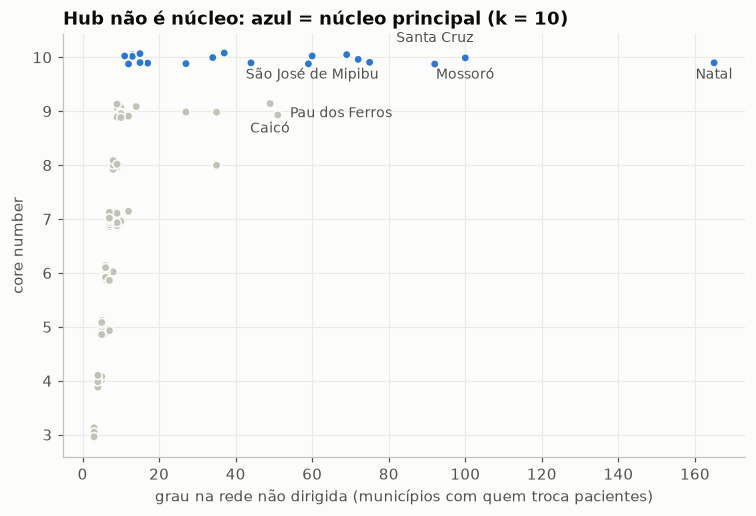

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
jitter = np.random.default_rng(SEMENTE).uniform(-0.15, 0.15, len(nos))
cor = np.where(nos["core"] == k_max, AZUL, CINZA)
ax.scatter(nos["grau_nao_dirigido"], nos["core"] + jitter, s=30, c=cor, edgecolor=FUNDO, linewidth=1, zorder=3)
deslocamento = {"Natal": (0, -14), "Mossoró": (0, -14), "Santa Cruz": (0, 10), "São José de Mipibu": (0, -14),
                "Pau dos Ferros": (8, -4), "Caicó": (0, -14)}
for cidade, (dx, dy) in deslocamento.items():
    c = cod[cidade]
    ax.annotate(cidade, (nos.at[c, "grau_nao_dirigido"], nos.at[c, "core"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=TINTA_2,
                ha="center" if dx == 0 else ("left" if dx > 0 else "right"))
ax.set_xlabel("grau na rede não dirigida (municípios com quem troca pacientes)")
ax.set_ylabel("core number")
ax.set_title(f"Hub não é núcleo: azul = núcleo principal (k = {k_max})")
salvar(fig, "06_grau_core.png")
plt.show()

**O núcleo principal no mapa.** Os municípios do núcleo (k = 10) e as ligações entre eles, na rede sem direção e sem peso usada pelo k-core. Pau dos Ferros e Caicó, que têm grau alto mas ficam fora do núcleo, aparecem em cinza.

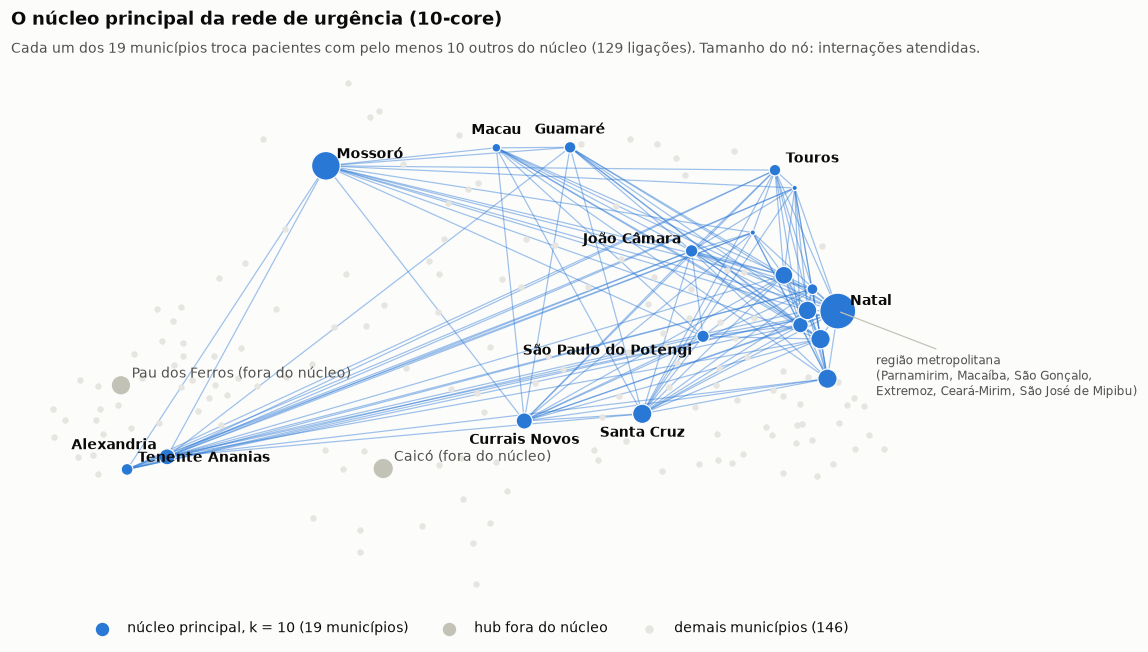

Ligações dentro do núcleo: 129; densidade do núcleo: 0.75 (rede inteira sem direção: 0.072)
Com quantos membros do núcleo cada um troca pacientes (menores): {'São Paulo do Potengi': 10, 'Tenente Ananias': 10, 'Pureza': 11, 'Guamaré': 11, 'Macau': 11}


In [37]:
nucleo = nx.k_core(K, k_max)
fora_nucleo = [o for o in K if o not in nucleo]
hubs_fora = [cod["Pau dos Ferros"], cod["Caicó"]]  # grau alto, fora do núcleo
tamanho = lambda nodos: [12 + 2.2 * np.sqrt(nos.at[o, "carga"]) for o in nodos]

fig, ax = plt.subplots(figsize=(12, 6.5))
nx.draw_networkx_nodes(K, pos, nodelist=fora_nucleo, node_size=10, node_color="#e6e5e0", ax=ax)
nx.draw_networkx_nodes(K, pos, nodelist=hubs_fora, node_size=tamanho(hubs_fora), node_color=CINZA,
                       edgecolors=FUNDO, linewidths=0.8, ax=ax)
nx.draw_networkx_edges(nucleo, pos, ax=ax, edge_color=AZUL, width=0.8, alpha=0.45)
nx.draw_networkx_nodes(nucleo, pos, nodelist=list(nucleo), node_size=tamanho(nucleo), node_color=AZUL,
                       edgecolors=FUNDO, linewidths=0.8, ax=ax)
deslocamento = {"Natal": (8, 4), "Mossoró": (7, 5), "Alexandria": (-7, 5), "Tenente Ananias": (7, 5),
                "Currais Novos": (0, -15), "Santa Cruz": (0, -15), "Macau": (0, 9), "Guamaré": (0, 9),
                "João Câmara": (-7, 5), "Touros": (7, 5), "São Paulo do Potengi": (-7, -12)}
for cidade, (dx, dy) in deslocamento.items():
    ax.annotate(cidade, pos[cod[cidade]], xytext=(dx, dy), textcoords="offset points", fontsize=9,
                fontweight="bold", color=TINTA, ha="center" if dx == 0 else ("left" if dx > 0 else "right"))
for c in hubs_fora:
    ax.annotate(f"{nome[c]} (fora do núcleo)", pos[c], xytext=(7, 5), textcoords="offset points", fontsize=9,
                color=TINTA_2)
ax.annotate("região metropolitana\n(Parnamirim, Macaíba, São Gonçalo,\nExtremoz, Ceará-Mirim, São José de Mipibu)",
            pos[cod["Natal"]], xytext=(25, -55), textcoords="offset points", fontsize=8, color=TINTA_2,
            arrowprops=dict(arrowstyle="-", color=CINZA, lw=0.8))
ax.scatter([], [], s=60, color=AZUL, label=f"núcleo principal, k = {k_max} ({nucleo.number_of_nodes()} municípios)")
ax.scatter([], [], s=60, color=CINZA, label="hub fora do núcleo")
ax.scatter([], [], s=20, color="#e6e5e0", label=f"demais municípios ({len(fora_nucleo) - len(hubs_fora)})")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=9)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"O núcleo principal da rede de urgência ({k_max}-core)", pad=22)
ax.text(0, 1.01, f"Cada um dos {nucleo.number_of_nodes()} municípios troca pacientes com pelo menos {k_max} outros do "
        f"núcleo ({nucleo.number_of_edges()} ligações). Tamanho do nó: internações atendidas.",
        transform=ax.transAxes, fontsize=9, color=TINTA_2)
salvar(fig, "06_nucleo_principal.png")
plt.show()

grau_no_nucleo = pd.Series(dict(nucleo.degree())).rename(index=nome).sort_values()
print(f"Ligações dentro do núcleo: {nucleo.number_of_edges()}; densidade do núcleo: {nx.density(nucleo):.2f} "
      f"(rede inteira sem direção: {nx.density(K):.3f})")
print("Com quantos membros do núcleo cada um troca pacientes (menores):", grau_no_nucleo.head(5).to_dict())

**O que a seção mostra:**

A decomposição k-core foi aplicada à versão não dirigida e não ponderada da rede, de modo que uma conexão indica apenas a existência de fluxo hospitalar entre dois municípios, independentemente de sua direção ou volume. A degenerescência encontrada foi \(k=10\), e o 10-core contém 19 municípios. Isso significa que, dentro desse subgrafo, cada município mantém ligação com pelo menos dez outros municípios do próprio núcleo, caracterizando uma região estruturalmente entrelaçada.

Os resultados também mostram que grau elevado não implica necessariamente pertencimento ao núcleo máximo. Caicó e Pau dos Ferros apresentam aproximadamente 50 vizinhos na rede completa, mas possuem core number 9. Portanto, embora sejam hubs regionais, parte significativa de suas conexões está associada a municípios que são removidos nas etapas anteriores da decomposição. Quando esses vizinhos deixam a rede residual, esses polos não mantêm grau suficiente para permanecer no 10-core. Assim, o grau mede a quantidade de conexões do município na rede original, enquanto o core number mede quão profundamente essas conexões estão sustentadas por uma estrutura também conectada.

A análise também é sensível à definição de uma ligação relevante. Como o k-core utilizado ignora os pesos, uma aresta associada a uma única internação possui o mesmo efeito estrutural que uma aresta contendo milhares de internações. Ao aplicar um limiar mínimo de cinco internações, a degenerescência cai de 10 para 5 e a composição do núcleo máximo muda, com Caicó passando a integrar o core mais profundo da rede filtrada. Isso não significa que Caicó tenha se tornado mais conectado, mas que a remoção das ligações fracas alterou a hierarquia estrutural da rede. Portanto, os resultados do k-core devem ser interpretados juntamente com uma análise de sensibilidade aos pesos e limiares.

## 7. Rede bipartida município ↔ hospital: quais hospitais atendem as mesmas populações?

*Semana 6 · `lesson08`: rede bipartida, projeção, artefato do clique e normalização de Jaccard.*

Até aqui, os municípios foram tratados como polos de atendimento, mas quem atende de fato são os hospitais. A rede bipartida tem dois conjuntos de nós: os municípios de residência (*M*) e os hospitais (*H*). Há uma aresta *m* ↔ *h* quando pelo menos `LIMIAR` internações de urgência de moradores de *m* aconteceram em *h* no ano, e o peso é o número de internações.

A projeção sobre os hospitais liga dois hospitais quando eles atendem moradores de pelo menos um mesmo município. A contagem de municípios em comum favorece hospitais de grande cobertura e produz o **artefato do clique**; por isso a comparação usa a similaridade de **Jaccard**:

$$J(A, B) = \frac{|N(A) \cap N(B)|}{|N(A) \cup N(B)|}$$

em que *N*(*A*) é o conjunto de municípios atendidos pelo hospital *A*. Jaccard alto indica hospitais com áreas de origem dos pacientes semelhantes: são **candidatos a alternativas de cobertura territorial**, e não necessariamente substitutos clínicos, porque a medida não considera especialidade, capacidade nem complexidade.

**Jaccard binário.** O Jaccard considera se cada município está ou não na área de atendimento do hospital (depois do limiar), e não o volume: um município com 10 internações em *A* e 5.000 em *B* conta como sobreposição do mesmo jeito.

A seção segue a lógica do resto do notebook (métrica → hipótese → teste de perturbação): 7.1 a rede bipartida e o artefato do clique; 7.2 o hospital mais parecido, no mesmo município e em outro; 7.3 a rede de hospitais semelhantes; 7.4 se um hospital parar, a cobertura se mantém?; 7.5 os substitutos dependem do limiar?

### 7.1 A rede bipartida e o artefato do clique

In [38]:
urg = df[df["CAMADA"] == "urgencia"]
fluxo_h = urg.groupby(["MUNIC_RES", "CNES"]).size()
fluxo_h = fluxo_h[fluxo_h >= LIMIAR]
hospitais = sorted(fluxo_h.index.get_level_values("CNES").unique())
municipio_do_hospital = urg.groupby("CNES")["MUNIC_MOV"].first()

B = nx.Graph()
B.add_nodes_from(nome.index, bipartite=0)
B.add_nodes_from(hospitais, bipartite=1)
B.add_weighted_edges_from((m, h, int(w)) for (m, h), w in fluxo_h.items())
print(f"Bipartida: {len(nome)} municípios, {len(hospitais)} hospitais, {B.number_of_edges()} ligações; "
      f"densidade {bipartite.density(B, list(nome.index)):.3f}")

contagem = bipartite.weighted_projected_graph(B, hospitais)
jaccard = bipartite.overlap_weighted_projected_graph(B, hospitais, jaccard=True)
print(f"Projeção nos hospitais: densidade {nx.density(contagem):.2f}")
grau_proj = pd.Series(dict(contagem.degree())).sort_values(ascending=False)
print("Hospitais com mais vizinhos na projeção (artefato do clique):")
for h in grau_proj.index[:3]:
    print(f"  {hospital[h]} ({nome[municipio_do_hospital[h]]}): ligado a {grau_proj[h]} de {len(hospitais) - 1}")

Bipartida: 167 municípios, 117 hospitais, 1152 ligações; densidade 0.059
Projeção nos hospitais: densidade 0.17
Hospitais com mais vizinhos na projeção (artefato do clique):
  HOSPITAL MONSENHOR WALFREDO GURGEL (Natal): ligado a 83 de 116
  HOSPITAL INFANTIL VARELA SANTIAGO (Natal): ligado a 76 de 116
  HOSPITAL DA LMECC (Mossoró): ligado a 69 de 116


### 7.2 O hospital mais parecido: no mesmo município e em outro

Para os 10 hospitais que mais recebem pacientes de outros municípios, o hospital com maior Jaccard em duas categorias: **no mesmo município** (redundância interna) e **em outro município** (alternativa regional, que importa se a estrutura local inteira falhar).

In [39]:
recebidas_h = urg[urg["MUNIC_RES"] != urg["MUNIC_MOV"]].groupby("CNES").size()
principais = recebidas_h.nlargest(10).index  # os 10 hospitais que mais recebem pacientes de outros municípios

def mais_parecido(h, mesma_cidade, G):
    """Hospital com maior Jaccard em relação a h, no mesmo município de h ou em outro."""
    if h not in G:
        return None, np.nan
    candidatos = [(v, d["weight"]) for v, d in G[h].items()
                  if (municipio_do_hospital[v] == municipio_do_hospital[h]) == mesma_cidade]
    return max(candidatos, key=lambda vj: vj[1], default=(None, np.nan))

linhas = []
for h in principais:
    mesma, j_mesma = mais_parecido(h, True, jaccard)
    outra, j_outra = mais_parecido(h, False, jaccard)
    linhas.append({
        "hospital": hospital[h], "município": nome[municipio_do_hospital[h]],
        "internações de fora": recebidas_h[h], "municípios atendidos": B.degree(h),
        "mais parecido no mesmo município": hospital[mesma] if mesma else "—",
        "J mesmo": round(j_mesma, 2),
        "mais parecido em outro município": f"{hospital[outra]} ({nome[municipio_do_hospital[outra]]})",
        "J outro": round(j_outra, 2),
    })
substitutos = pd.DataFrame(linhas).set_index("hospital")
substitutos

,município,internações de fora,municípios atendidos,mais parecido no mesmo município,J mesmo,mais parecido em outro município,J outro
hospital,,,,,,,
HOSPITAL MONSENHOR WALFREDO GURGEL,Natal,11779,107,MATERNIDADE ESCOLA JANUARIO CICCO,0.62,HOSPITAL UNIVERSITARIO ANA BEZERRA (Santa Cruz),0.38
HOSPITAL MATERNIDADE ALMEIDA CASTRO,Mossoró,5275,54,HOSPITAL REGIONAL DR TARCISIO DE VASCONCELOS MAIA,0.71,HOSPITAL REGIONAL DR CLEODON CARLOS DE ANDRADE...,0.41
HOSPITAL DR JOSE PEDRO BEZERRA,Natal,4992,35,HOSPITAL CENTRAL CORONEL PEDRO GERMANO,0.38,HOSPITAL DR PERCILIO ALVES DE OLIVEIRA (Ceará-...,0.63
MATERNIDADE ESCOLA JANUARIO CICCO,Natal,3932,71,HOSPITAL MONSENHOR WALFREDO GURGEL,0.62,HOSPITAL UNIVERSITARIO ANA BEZERRA (Santa Cruz),0.44
HOSPITAL REGIONAL MONSENHOR ANTONIO BARROS,São José de Mipibu,3866,25,—,NaN,HOSPITAL REGIONAL LINDOLFO GOMES VIDAL (Santo ...,0.66
HOSPITAL REGIONAL DR TARCISIO DE VASCONCELOS MAIA,Mossoró,3843,40,HOSPITAL WILSON ROSADO,0.72,HOSPITAL REGIONAL NELSON INACIO DOS SANTOS (Assú),0.23
HOSPITAL UNIVERSITARIO ANA BEZERRA,Santa Cruz,3313,41,HOSPITAL MUNICIPAL ALUIZIO BEZERRA,0.02,HOSPITAL DR MARIANO COELHO (Currais Novos),0.45
HOSPITAL REGIONAL DR CLEODON CARLOS DE ANDRADE,Pau dos Ferros,3198,39,HOSPITAL DR NELSON MAIA,0.28,HOSPITAL DA LMECC (Mossoró),0.42
HOSPITAL INFANTIL VARELA SANTIAGO,Natal,3125,66,HOSPITAL CENTRAL CORONEL PEDRO GERMANO,0.51,HOSPITAL REGIONAL MONSENHOR ANTONIO BARROS (Sã...,0.26


### 7.3 A rede de hospitais semelhantes

A projeção filtrada por Jaccard ≥ 0,5, só com hospitais que atendem pelo menos 3 municípios. Com 1 ou 2 municípios, Jaccard = 1 é trivial: dois hospitais que só atendem moradores de Natal ficariam "idênticos". Cada grupo ligado é um conjunto de hospitais com áreas de origem parecidas.

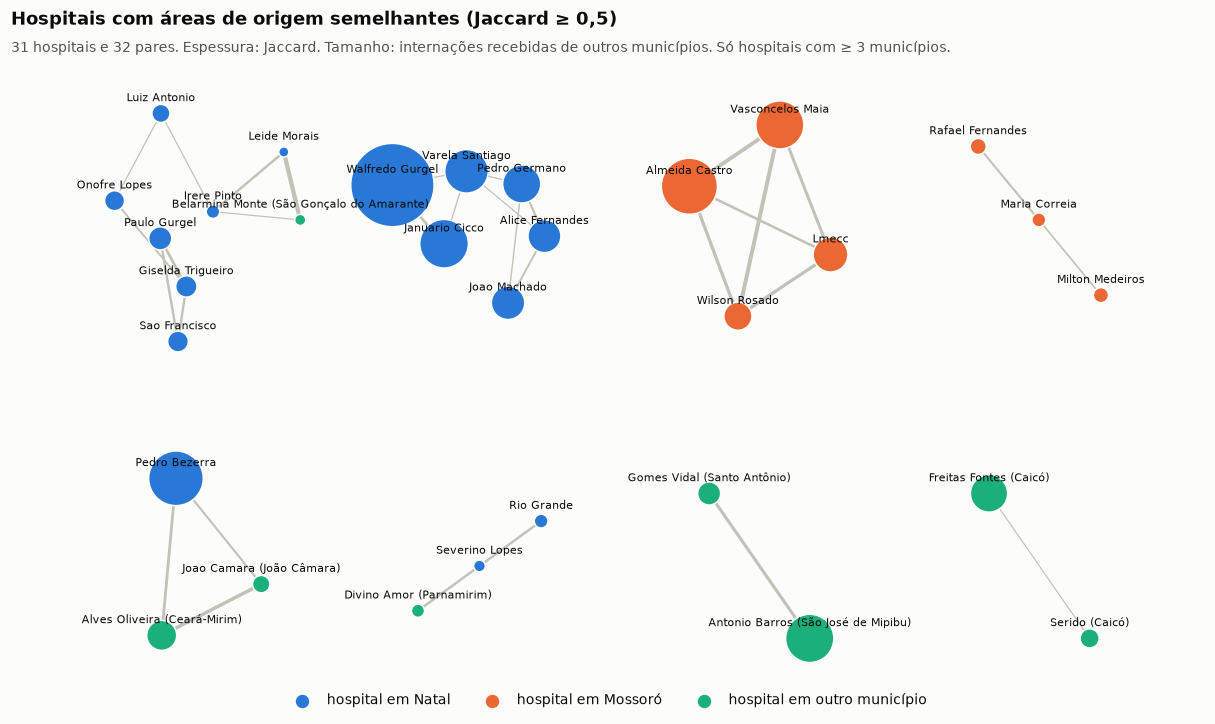

Grupos de hospitais semelhantes: 8
  8: Hospital Dr Luiz Antonio (Natal); Hospital Giselda Trigueiro (Natal); Hospital Maternidade Belarmina Monte (São Gonçalo do Amarante); Hospital Memorial Sao Francisco (Natal); Hospital Universitario Onofre Lopes (Natal); Maternidade Araken Irere Pinto (Natal); Maternidade Professor Leide Morais (Natal); Prontoclinica Da Crianca Dr Paulo Gurgel (Natal)
  6: Hospital Central Coronel Pedro Germano (Natal); Hospital Geral Dr Joao Machado (Natal); Hospital Infantil Varela Santiago (Natal); Hospital Maria Alice Fernandes (Natal); Hospital Monsenhor Walfredo Gurgel (Natal); Maternidade Escola Januario Cicco (Natal)
  4: Hospital Da Lmecc (Mossoró); Hospital Maternidade Almeida Castro (Mossoró); Hospital Regional Dr Tarcisio De Vasconcelos Maia (Mossoró); Hospital Wilson Rosado (Mossoró)
  3: Hospital Psiquiatrico De Mossoro Dr Milton Marq De Medeiros (Mossoró); Hospital Rafael Fernandes (Mossoró); Hospital Regional Da Mulher Parteira Maria Correia (Mosso

In [40]:
J_MIN, MIN_MUNICIPIOS = 0.5, 3  # só hospitais com pelo menos 3 municípios: com 1 ou 2, Jaccard = 1 é trivial
com_area = [h for h in hospitais if B.degree(h) >= MIN_MUNICIPIOS]
similares = nx.Graph()
similares.add_edges_from((a, b, {"weight": j}) for a, b, j in jaccard.subgraph(com_area).edges(data="weight")
                         if j >= J_MIN)
# cada grupo (componente) desenhado na sua própria célula, para grupos diferentes não se sobreporem
grupos = sorted(nx.connected_components(similares), key=len, reverse=True)
pos_h = {}
for k, conjunto in enumerate(grupos):
    sub = nx.spring_layout(similares.subgraph(conjunto), seed=SEMENTE, k=1.2)
    escala = 1.15 * np.sqrt(len(conjunto) / len(grupos[0]))
    cx, cy = 3.2 * (k % 4), -2.7 * (k // 4)
    pos_h.update({h: (cx + escala * x, cy + escala * y) for h, (x, y) in sub.items()})
cidade = {h: nome[municipio_do_hospital[h]] for h in similares}
cor_cidade = {"Natal": AZUL, "Mossoró": LARANJA}
cor_h = [cor_cidade.get(cidade[h], VERDE) for h in similares]
tam_h = [30 + 0.25 * recebidas_h.get(h, 0) for h in similares]

def curto(h):
    """Nome curto: as duas últimas palavras do nome, sem preposições e títulos."""
    fora = {"Hospital", "Regional", "Dr", "De", "Da", "Do", "Dos", "Maternidade", "Escola", "Marq"}
    palavras = [p for p in hospital[h].title().split() if p not in fora]
    rotulo = " ".join(palavras[-2:])
    return rotulo if cidade[h] in cor_cidade else f"{rotulo} ({cidade[h]})"

fig, ax = plt.subplots(figsize=(14, 7.5))
nx.draw_networkx_edges(similares, pos_h, ax=ax, edge_color=CINZA,
                       width=[4 * (d["weight"] - J_MIN) / (1 - J_MIN) + 0.8 for *_, d in similares.edges(data=True)])
nx.draw_networkx_nodes(similares, pos_h, ax=ax, node_color=cor_h, node_size=tam_h, edgecolors=FUNDO, linewidths=1)
for h, (x, y) in pos_h.items():
    ax.annotate(curto(h), (x, y), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=7.5, color=TINTA)
for rotulo, cor in [("hospital em Natal", AZUL), ("hospital em Mossoró", LARANJA), ("hospital em outro município", VERDE)]:
    ax.scatter([], [], s=60, color=cor, label=rotulo)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=3, fontsize=9)
ax.axis("off")
ax.set_title(f"Hospitais com áreas de origem semelhantes (Jaccard ≥ {str(J_MIN).replace('.', ',')})", pad=22)
ax.text(0, 1.01, f"{similares.number_of_nodes()} hospitais e {similares.number_of_edges()} pares. Espessura: Jaccard. "
        f"Tamanho: internações recebidas de outros municípios. Só hospitais com ≥ {MIN_MUNICIPIOS} municípios.",
        transform=ax.transAxes, fontsize=9, color=TINTA_2)
salvar(fig, "07_rede_jaccard.png")
plt.show()

print(f"Grupos de hospitais semelhantes: {len(grupos)}")
for conjunto in grupos:
    print(f"  {len(conjunto)}: " + "; ".join(sorted(f"{hospital[h].title()} ({cidade[h]})" for h in conjunto)))

### 7.4 Se um hospital parar, a cobertura se mantém?

O Jaccard aponta quem parece substituto; a remoção testa se a substituição preserva a cobertura. Para cada um dos 10 hospitais principais:

- **R(*h*):** municípios que ficariam sem nenhuma rota estabelecida para hospital nenhum (o hospital era a única ligação com pelo menos `LIMIAR` internações);
- **dependentes:** municípios em que o hospital atende mais da metade das urgências;
- para os dependentes, onde fica o hospital que eles mais usam depois desse (no mesmo município do hospital removido ou em outro) e quantas horas a mais de viagem isso dá.

In [41]:
# uso: urgências de cada município em cada hospital (todas); B: só as rotas estabelecidas (>= LIMIAR)
uso = urg.groupby(["MUNIC_RES", "CNES"]).size()
total_municipio = uso.groupby(level=0).sum()
linhas = []
for h in principais:
    cidade_h = municipio_do_hospital[h]
    sem_alternativa = [m for m in B.neighbors(h) if B.degree(m) == 1]
    dependentes = [m for m in B.neighbors(h) if uso[(m, h)] / total_municipio[m] > 0.5]
    mesma, outra, horas_extra = 0, 0, []
    for m in dependentes:
        alternativas = {v: B[m][v]["weight"] for v in B.neighbors(m) if v != h}
        if not alternativas:
            continue
        alt = max(alternativas, key=alternativas.get)  # hospital mais usado depois de h
        if municipio_do_hospital[alt] == cidade_h:
            mesma += 1
        else:
            outra += 1
            horas_extra.append(horas(m, municipio_do_hospital[alt]) - horas(m, cidade_h))
    linhas.append({
        "hospital": hospital[h], "município": nome[cidade_h],
        "R(h): sem nenhuma alternativa": len(sem_alternativa),
        "dependem dele (> 50% das urgências)": len(dependentes),
        "alternativa no mesmo município": mesma,
        "alternativa em outro município": outra,
        "horas a mais (média)": round(np.mean(horas_extra), 1) if horas_extra else np.nan,
    })
print("Municípios sem nenhuma rota estabelecida para hospital:", sum(B.degree(m) == 0 for m in nome.index))
print("Municípios com uma só rota estabelecida (R > 0):",
      [f"{nome[m]} -> {hospital[next(iter(B[m]))].title()}" for m in nome.index if B.degree(m) == 1])
remocao_h = pd.DataFrame(linhas).set_index("hospital")
remocao_h

Municípios sem nenhuma rota estabelecida para hospital: 0
Municípios com uma só rota estabelecida (R > 0): ['Viçosa -> Hospital Regional Dr Cleodon Carlos De Andrade']


,município,R(h): sem nenhuma alternativa,dependem dele (> 50% das urgências),alternativa no mesmo município,alternativa em outro município,horas a mais (média)
hospital,,,,,,
HOSPITAL MONSENHOR WALFREDO GURGEL,Natal,0,0,0,0,NaN
HOSPITAL MATERNIDADE ALMEIDA CASTRO,Mossoró,0,0,0,0,NaN
HOSPITAL DR JOSE PEDRO BEZERRA,Natal,0,0,0,0,NaN
MATERNIDADE ESCOLA JANUARIO CICCO,Natal,0,0,0,0,NaN
HOSPITAL REGIONAL MONSENHOR ANTONIO BARROS,São José de Mipibu,0,0,0,0,NaN
HOSPITAL REGIONAL DR TARCISIO DE VASCONCELOS MAIA,Mossoró,0,0,0,0,NaN
HOSPITAL UNIVERSITARIO ANA BEZERRA,Santa Cruz,0,1,0,1,1.5
HOSPITAL REGIONAL DR CLEODON CARLOS DE ANDRADE,Pau dos Ferros,1,10,4,5,1.4
HOSPITAL INFANTIL VARELA SANTIAGO,Natal,0,0,0,0,NaN


### 7.5 Os substitutos dependem do limiar?

O conjunto *N*(*h*) depende do `LIMIAR`, e portanto o Jaccard também. A tabela refaz o substituto em outro município com limiares 1, 5, 10 e 20 (entre parênteses, o Jaccard). Se o substituto se mantém, a semelhança não depende de fluxos raros.

In [42]:
linhas = []
for lim in [1, 5, 10, 20]:
    fluxo_l = urg.groupby(["MUNIC_RES", "CNES"]).size()
    fluxo_l = fluxo_l[fluxo_l >= lim]
    hosp_l = sorted(fluxo_l.index.get_level_values("CNES").unique())
    B_l = nx.Graph()
    B_l.add_nodes_from(nome.index, bipartite=0)
    B_l.add_nodes_from(hosp_l, bipartite=1)
    B_l.add_edges_from(fluxo_l.index)
    J_l = bipartite.overlap_weighted_projected_graph(B_l, hosp_l, jaccard=True)
    clique = bipartite.projected_graph(B_l, hosp_l)
    for h in principais:
        outra, j = mais_parecido(h, False, J_l)
        linhas.append({"hospital": hospital[h], "limiar": lim,
                       "substituto em outro município": f"{nome[municipio_do_hospital[outra]]} ({j:.2f})" if outra else "—"})
    walfredo = next(h for h in hosp_l if "WALFREDO" in hospital[h])
    print(f"Limiar {lim:>2}: {len(hosp_l)} hospitais, {B_l.number_of_edges()} ligações; "
          f"Walfredo Gurgel ligado a {clique.degree(walfredo)} hospitais na projeção por contagem")
sensibilidade = pd.DataFrame(linhas).pivot(index="hospital", columns="limiar", values="substituto em outro município")
sensibilidade["mesma cidade substituta nos 4 limiares?"] = sensibilidade.apply(
    lambda linha: len({v.split(" (")[0] for v in linha}) == 1, axis=1)
sensibilidade.loc[[hospital[h] for h in principais]]

Limiar  1: 120 hospitais, 3117 ligações; Walfredo Gurgel ligado a 112 hospitais na projeção por contagem
Limiar  5: 119 hospitais, 1606 ligações; Walfredo Gurgel ligado a 94 hospitais na projeção por contagem
Limiar 10: 117 hospitais, 1152 ligações; Walfredo Gurgel ligado a 83 hospitais na projeção por contagem
Limiar 20: 111 hospitais, 792 ligações; Walfredo Gurgel ligado a 73 hospitais na projeção por contagem


limiar,1,5,10,20,mesma cidade substituta nos 4 limiares?
hospital,,,,,
HOSPITAL MONSENHOR WALFREDO GURGEL,Santa Cruz (0.61),Santa Cruz (0.40),Santa Cruz (0.38),Santa Cruz (0.33),True
HOSPITAL MATERNIDADE ALMEIDA CASTRO,Pau dos Ferros (0.56),Pau dos Ferros (0.52),Pau dos Ferros (0.41),Pau dos Ferros (0.23),True
HOSPITAL DR JOSE PEDRO BEZERRA,Santa Cruz (0.67),João Câmara (0.48),Ceará-Mirim (0.63),Ceará-Mirim (0.69),False
MATERNIDADE ESCOLA JANUARIO CICCO,Santa Cruz (0.72),Santa Cruz (0.54),Santa Cruz (0.44),São José de Mipibu (0.36),False
HOSPITAL REGIONAL MONSENHOR ANTONIO BARROS,Macaíba (0.59),Santo Antônio (0.58),Santo Antônio (0.66),Santo Antônio (0.59),False
HOSPITAL REGIONAL DR TARCISIO DE VASCONCELOS MAIA,Pau dos Ferros (0.53),Pau dos Ferros (0.37),Assú (0.23),Assú (0.19),False
HOSPITAL UNIVERSITARIO ANA BEZERRA,Natal (0.75),Natal (0.54),Currais Novos (0.45),São Paulo do Potengi (0.34),False
HOSPITAL REGIONAL DR CLEODON CARLOS DE ANDRADE,Mossoró (0.61),Mossoró (0.52),Mossoró (0.42),Mossoró (0.23),True
HOSPITAL INFANTIL VARELA SANTIAGO,Santa Cruz (0.62),Santa Cruz (0.30),São José de Mipibu (0.26),São José de Mipibu (0.29),False


**O que a seção mostra.**

- **Artefato do clique (7.1).** O Hospital Walfredo Gurgel (Natal) atende 107 municípios e, na projeção por contagem, se liga a 83 dos 116 outros hospitais (112 com limiar 1, 73 com limiar 20). A contagem revela hubs; o Jaccard revela pares proporcionalmente parecidos.
- **Redundância interna (7.2 e 7.3).** Em Mossoró, quatro hospitais (Tarcísio Maia, Wilson Rosado, Almeida Castro e LMECC) formam um grupo, com Jaccard de 0,71 a 0,72 entre os principais: se um parar, outro da mesma cidade já atende os mesmos municípios. Natal tem dois grupos grandes, e Caicó tem um par (Hospital do Seridó e Telecila Freitas Fontes). O risco da seção 5 é o município de Mossoró inteiro parar de absorver, e não um hospital isolado.
- **Alternativas regionais (7.2).** O hospital mais parecido em outro município confirma as segundas opções da seção 5: para o Regional de Pau dos Ferros, um hospital de Mossoró (0,42); para o Regional de São José de Mipibu, o de Santo Antônio (0,66). O José Pedro Bezerra (Natal) se parece com o hospital de Ceará-Mirim (0,63), no mesmo grupo do hospital de João Câmara.
- **A substituição preserva a cobertura? (7.4).** No nível de hospital, quase ninguém fica sem alternativa: só Viçosa depende de um único hospital, o Regional de Pau dos Ferros. Esse hospital atende mais da metade das urgências de 10 municípios; sem ele, 4 têm alternativa na própria Pau dos Ferros, 5 precisariam ir a outra cidade (1,4 h a mais, em média) e Viçosa fica sem rota. Os hospitais de Natal e de Mossoró não têm municípios dependentes: a demanda se divide entre vários hospitais da mesma cidade.
- **Robustez (7.5).** Pau dos Ferros → Mossoró e Almeida Castro (Mossoró) → Pau dos Ferros se mantêm nos 4 limiares; São José de Mipibu → Santo Antônio, de 5 a 20. O par do Hospital Universitário Ana Bezerra (Santa Cruz) muda com o limiar (Natal, Currais Novos ou São Paulo do Potengi): essa semelhança depende de fluxos pequenos e não deve ser usada como conclusão.
- **Limite do Jaccard.** Mesmos municípios atendidos não são os mesmos serviços: o hospital mais parecido com o Walfredo Gurgel (trauma) no mesmo município é a Maternidade Januário Cicco (0,62), porque os dois recebem pacientes dos mesmos municípios.

## 8. Robustez: as conclusões dependem do limiar?

*Semana 6 · `lesson08` §5.7: esqueleto por limiar de peso.*

Um terço das arestas tem 1 ou 2 internações no ano. Subindo o limiar, as ligações fracas saem primeiro e fica o esqueleto. Se as conclusões mudassem muito com o limiar, elas dependeriam de casos isolados.

In [43]:
linhas = []
for limiar in [1, 5, 10, 20, 30]:
    H = acima_do_limiar(U, limiar)
    core = pd.Series(nx.core_number(H.to_undirected()))
    forca_h = pd.Series(dict(H.in_degree(weight="weight")))
    mossoro, _, _ = cenario(H, cod["Mossoró"])
    caico, _, _ = cenario(H, cod["Caicó"])
    linhas.append({
        "limiar": limiar,
        "arestas": H.number_of_edges(),
        "fluxo mantido": forca_h.sum() / nos["forca_entrada"].sum(),
        "5 maiores polos": ", ".join(nome[forca_h.nlargest(5).index]),
        "degenerescência": core.max(),
        "Natal no núcleo?": core[cod["Natal"]] == core.max(),
        "Caicó no núcleo?": core[cod["Caicó"]] == core.max(),
        "sem Mossoró: h depois": mossoro["horas depois (de fora)"],
        "sem Mossoró: sem alternativa": mossoro["sem alternativa"],
        "sem Caicó: h depois": caico["horas depois (de fora)"],
    })
pd.DataFrame(linhas).set_index("limiar").round(2)

,arestas,fluxo mantido,5 maiores polos,degenerescência,Natal no núcleo?,Caicó no núcleo?,sem Mossoró: h depois,sem Mossoró: sem alternativa,sem Caicó: h depois
limiar,,,,,,,,,
1,1069,1.00,"Natal, Mossoró, São José de Mipibu, Pau dos Fe...",10,True,False,2.76,0,3.06
5,602,0.99,"Natal, Mossoró, São José de Mipibu, Pau dos Fe...",5,True,True,2.98,435,3.15
10,484,0.98,"Natal, Mossoró, São José de Mipibu, Pau dos Fe...",4,True,True,3.02,1214,3.21
20,391,0.96,"Natal, Mossoró, São José de Mipibu, Pau dos Fe...",4,True,True,2.87,4000,3.25
30,336,0.94,"Natal, Mossoró, São José de Mipibu, Pau dos Fe...",4,True,True,2.70,5948,3.29


**O que a seção mostra.**

- **O que é robusto.** Os 5 maiores polos são os mesmos em todos os limiares. Com limiar 30 ficam só 336 das 1.069 arestas, mas 94% do fluxo: dois terços das ligações carregam 6% das internações. O tempo de viagem sem Mossoró (2,7 a 3,0 h) e sem Caicó (3,1 a 3,3 h) quase não muda.
- **O que depende do limiar.** O número de internações "sem alternativa" depende do que se aceita como alternativa: 0 com qualquer ligação, 1.214 sem Mossoró com limiar 10, 5.948 com limiar 30. Por isso o notebook mostra as duas versões. O k-core também muda (degenerescência de 10 para 4), como discutido na seção 6.

## 9. Exportar para o Gephi

*Semana 5 · Gephi (layouts, medidas e publicação).*

Dois arquivos em `data/processed/`, com os atributos calculados no notebook. No Gephi, eles aparecem no *Data Laboratory* e servem para cor, tamanho e filtros.

**1. `rede_rn_2024_urgencia.graphml`**: a rede de urgência (167 municípios, 1.069 ligações).

| atributo do nó | o que é | seção | sugestão no Gephi |
|---|---|---|---|
| `label`, `latitude`, `longitude` | nome e posição da sede | – | layout geográfico (plugin *Geo Layout*) |
| `grau_entrada`, `grau_saida`, `forca_entrada`, `forca_saida` | graus e forças | 1.3 | tamanho do nó: `forca_entrada` |
| `locais`, `residentes`, `autossuficiencia`, `carga` | atendimento no próprio município | 1.3, 1.4 | cor (*Ranking*): `autossuficiencia` |
| `bacia`, `grupo_bacia`, `camada_bfs` | bacia (BFS) e camada | 1.4 | cor (*Partition*): `grupo_bacia` |
| `destino_principal`, `dependencia` | dependência de polo único | 2 | cor (*Ranking*): `dependencia` |
| `na_maior_scc` | está na maior componente forte | 3.1 | cor (*Partition*) |
| `closeness`, `betweenness` | centralidades | 4 | tamanho ou cor |
| `horas_ate_principal`, `horas_sem_principal`, `horas_a_mais`, `sem_rota_alternativa` | vulnerabilidade se o destino principal parar | 5.2 | cor (*Ranking*): `horas_a_mais` |
| `grau_nao_dirigido`, `core`, `nucleo_principal` | decomposição em núcleos | 6 | filtro: `nucleo_principal` |

| atributo da aresta | o que é | sugestão no Gephi |
|---|---|---|
| `weight` | internações no ano | espessura; filtro `weight ≥ 10` = rotas estabelecidas (3.2) |
| `fracao` | fração das urgências dos residentes da origem | espessura alternativa |
| `horas`, `km_estrada` | tempo e distância de carro entre as sedes | – |
| `ida_e_volta` | o par troca pacientes nos dois sentidos | filtro: a maior SCC (3.1) |

**2. `rede_hospitais_jaccard_2024.graphml`**: a rede de hospitais semelhantes da seção 7.3 (Jaccard ≥ 0,5), com nome, município, internações recebidas de fora e municípios atendidos. Espessura da aresta: `weight` (Jaccard).

In [44]:
# --- rede de urgência: atributos dos nós, na ordem das seções
tamanho_bacia = nos["bacia"].value_counts()
nos["grupo_bacia"] = nos["bacia"].map(lambda b: nome[b] if tamanho_bacia[b] > 1 else PROPRIA)
nos["nucleo_principal"] = nos["core"] == k_max
colunas = ["grau_entrada", "grau_saida", "forca_entrada", "forca_saida",              # 1.3
           "locais", "residentes", "autossuficiencia", "carga",                        # 1.3, 1.4
           "bacia", "grupo_bacia", "camada_bfs",                                       # 1.4
           "destino_principal", "dependencia",                                         # 2
           "na_maior_scc",                                                             # 3.1
           "closeness", "betweenness",                                                 # 4
           "horas_ate_principal", "horas_sem_principal", "horas_a_mais", "sem_rota_alternativa",  # 5.2
           "grau_nao_dirigido", "core", "nucleo_principal"]                            # 6
atributos = nos[colunas].join(coord).assign(
    label=nos["nome"],
    bacia=nos["bacia"].map(nome),
    destino_principal=nos["destino_principal"].map(nome),
)

def valor(v):
    """Tipos que o GraphML aceita (numpy -> Python)."""
    return v.item() if hasattr(v, "item") else v

G_gephi = U.copy()
for c, attrs in atributos.to_dict("index").items():
    G_gephi.nodes[c].update({k: valor(v) for k, v in attrs.items() if pd.notna(v)})
for o, v, d in G_gephi.edges(data=True):
    d["horas"] = horas(o, v)
    d["km_estrada"] = float(dist.at[(o, v), "km_estrada"])
    d["fracao"] = d["weight"] / nos.at[o, "residentes"]
    d["ida_e_volta"] = U.has_edge(v, o)
nx.write_graphml(G_gephi, PROCESSED / f"rede_rn_{ANO}_urgencia.graphml")
atributos.to_csv(PROCESSED / f"nos_rn_{ANO}_urgencia.csv")
print(f"rede_rn_{ANO}_urgencia.graphml: {G_gephi.number_of_nodes()} nós, {G_gephi.number_of_edges()} arestas")
print("  atributos dos nós:", ", ".join(atributos.columns))

# --- rede de hospitais semelhantes (seção 7.3)
H_gephi = similares.copy()
for h in H_gephi:
    H_gephi.nodes[h].update({"label": hospital[h].title(), "municipio": nome[municipio_do_hospital[h]],
                             "internacoes_de_fora": int(recebidas_h.get(h, 0)), "municipios_atendidos": B.degree(h)})
nx.write_graphml(H_gephi, PROCESSED / f"rede_hospitais_jaccard_{ANO}.graphml")
print(f"rede_hospitais_jaccard_{ANO}.graphml: {H_gephi.number_of_nodes()} hospitais, {H_gephi.number_of_edges()} pares")

rede_rn_2024_urgencia.graphml: 167 nós, 1069 arestas
  atributos dos nós: grau_entrada, grau_saida, forca_entrada, forca_saida, locais, residentes, autossuficiencia, carga, bacia, grupo_bacia, camada_bfs, destino_principal, dependencia, na_maior_scc, closeness, betweenness, horas_ate_principal, horas_sem_principal, horas_a_mais, sem_rota_alternativa, grau_nao_dirigido, core, nucleo_principal, latitude, longitude, label
rede_hospitais_jaccard_2024.graphml: 31 hospitais, 32 pares


## 10. Síntese

### Resposta à pergunta

**1. Quem sustenta o acesso** (seções 1 e 4). Natal recebe metade das internações de urgência entre municípios (33.471) e Mossoró, 20% (13.340); os 5 maiores polos recebem 85%. Os municípios se organizam em 5 bacias grandes, Natal (78), Mossoró (29), Pau dos Ferros (22), Caicó (11) e Santa Cruz (6), e as bacias são estrelas: pela BFS, 140 dos 141 municípios que não são polo apontam direto para o polo.

**2. Quanto cada município depende de um polo** (seções 1.3 e 2). 83 municípios não tiveram nenhuma internação de urgência no próprio município em 2024. 129 mandam mais da metade das urgências que saem do município para um único polo, e 65 mandam mais de 70%. Ter muitos destinos não é independência: Parnamirim manda pacientes para 15 municípios, mas 97% do que sai vai para Natal.

**3. Se um polo parar** (seções 3.2 e 5).

| polo | internações afetadas por ano | tempo médio de quem vem de fora | internações sem rota estabelecida | municípios isolados (3.2) |
|---|---|---|---|---|
| Natal | 60 mil | 1,3 h → 0,9 h, mas Macaíba teria de atender 7,8× o volume atual | 70 | 1 (Galinhos) |
| Mossoró | 24 mil | 1,4 h → 2,8 h (moradores de Mossoró: 4,1 h) | 1.214 | 5 |
| Caicó | 5,7 mil | 0,8 h → 3,1 h | 70 | 1 (Ipueira) |
| Pau dos Ferros | 4,7 mil | 0,7 h → 2,7 h | 32 | 1 (Viçosa) |

A rede é um bloco só e tolera falhas ao acaso, mas não a perda dos polos (seção 5.3).

**Dois tipos de polo crítico** (seção 4.6). As centralidades apontam Natal em 1º lugar em todas as medidas, mas a remoção mostra duas criticidades diferentes:

- **Mossoró é o mais crítico para a conectividade:** sem ele, 5 municípios ficam sem rota estabelecida (13 com rotas de pelo menos 20 internações).
- **Natal é o mais crítico para a carga:** quase ninguém fica sem rota, mas nenhum município vizinho consegue absorver o volume.

**No nível de hospital** (seção 7). Natal e Mossoró têm redundância interna: vários hospitais da mesma cidade atendem os mesmos municípios, e nenhum município depende de um hospital só. O ponto único é o Hospital Regional de Pau dos Ferros: atende mais da metade das urgências de 10 municípios, e sem ele 5 precisariam ir a outra cidade e Viçosa ficaria sem rota.

**Robustez** (seções 7.5 e 8). Os 5 maiores polos, os tempos de viagem e os substitutos de Pau dos Ferros e de Mossoró se mantêm em todos os limiares. O número de internações "sem rota estabelecida" e o k-core dependem do limiar, e por isso o notebook mostra as duas versões.

### Prioridades para a gestão

- **Mossoró**, o polo cuja falha deixa mais municípios sem rota estabelecida (5 dos 8: Tibau, Governador Dix-Sept Rosado, Triunfo Potiguar, Paraú, Janduís) e cuja carga cairia sobre Natal.
- **Pau dos Ferros e Caicó**, onde a falha mais aumenta o tempo de viagem. Pau dos Ferros depende de Mossoró como alternativa: se os dois falharem juntos e a alternativa for Natal, os 22 municípios da bacia de Pau dos Ferros ficam a 5,2 a 6,9 h de viagem (média de 5,9 h). O Hospital Regional de Pau dos Ferros é o hospital mais difícil de substituir.
- **Natal**, que não tem substituto em volume: qualquer redução de capacidade em Natal se espalha pela rede inteira.

### Limitações

- **Competência.** Os arquivos do SIH são por mês de processamento: 6% das AIHs de 2024 são de internações de 2023.
- **Unidade.** A unidade é a AIH, não o paciente: transferências e reinternações contam de novo.
- **Só o que aconteceu.** O SIH registra internações realizadas pelo SUS. Não mede demanda reprimida (quem não conseguiu vaga) nem internações por plano de saúde ou particulares.
- **Urgência inclui partos.** Por isso maternidades regionais aparecem como polos de urgência.
- **Rota estabelecida.** O limiar de 10 internações por ano é uma escolha do projeto, não uma regra oficial; a seção 8 testa de 1 a 30.
- **Bacias.** Cada município entra numa só bacia, a do destino mais usado; um município que divide as urgências quase igualmente entre dois destinos fica só com um.
- **Redistribuição é hipótese.** O cenário supõe que os pacientes seguem as alternativas que o município já usa, na mesma proporção. Na prática a regulação estadual decide.
- **Carga não é capacidade.** O "7,8×" de Macaíba compara com o volume atendido hoje, não com o número de leitos.
- **Distância.** Tempo de carro entre as sedes dos municípios (OSRM sobre o OpenStreetMap), não da casa do paciente ao hospital.
- **Betweenness.** Caminhos de vários passos não são trajetos de pacientes; a betweenness mede posição estrutural.
- **Jaccard.** É binário (presença do município, não volume) e mede se dois hospitais atendem a mesma população, não se oferecem o mesmo serviço.
- **k-core.** A hierarquia de núcleos depende das ligações fracas (seção 8).